**PoCT - Toxoplasmosis Diagnosis Device (Dec, 2026)**  
Dodit Suprianto  
Email: Dodit.suprianto@polinema.ac.id  
Affiliation:  
- Department of Electrical Engineering, Politeknik Negeri Malang, Malang, Indonesia  
- AIDS, Toxoplasma, Opportunistic Disease and Malaria (ATOM) Research Group, Faculty of Medicine, Universitas Brawijaya, Malang, Indonesia

---

# Artefact-Free Classification of Anti-GRA7 Dot-Blot Assays for *Toxoplasma gondii* — New Pipeline

**Objective.** To rebuild the quantification → machine-learning (ML) and deep-learning (CNN) stages for classifying dot-blot spots (positive/negative, CLIA reference), with a focus on **removing morphological artefacts** (circular shape caused by pressing/cropping) as a source of discriminative signal.

**Starting point:** grayscale images produced by segmentation + *auto-cropping* (3 tests × 5 illumination levels: 250, 350, 470, 560, 850 lux). The camera device, YOLOv8-seg segmentation and cropping are **not** repeated here.

## Design principles (how this notebook addresses weaknesses of a morphology-based approach)
| Problem | Remedy in this notebook |
|---|---|
| "Significant" features = morphology (area, perimeter, circularity) → pressing & cropping artefacts | Shape features are **excluded** from the main models and used only as a **negative control** (*shape-only baseline*). Quantification is based on **ROI content** (inner disk), not on the contour |
| Raw densitometry does not separate the classes | Conversion to **Optical Density** (Beer–Lambert), local background correction, **radial profile**, power spectrum and **rotation-invariant** texture, between-membrane normalisation |
| Membrane 1 contains 100% positive samples → *batch confound* | Batch diagnostics, per-membrane normalisation, and the **MIX** protocol (Membranes 2+3, both classes on the same membrane) as a confound-free evaluation |
| Pseudo-replication (4 replicates/sample; 2× on M2/M3) | All validation uses **Stratified Group K-Fold at the serum-sample level** (no leakage), repeated several times; metrics reported at the spot **and** sample level |
| IQR/MAD outlier filtering on feature values (removing 38 spots) | QC only for **acquisition failures** (blank/truncated crops), never on feature values |
| Only SVM/RF/XGB on 5 morphological features | 9 ML algorithms × 6 quantification methods + controls; 5 CNN architectures + *mask-only* control; *nested* tuning |

## Workflow
```
Grayscale images ──► EDA & artefact diagnostics ──► Cleansing (acquisition QC)
        ├──► [Pipeline A] Quantification (Q1–Q6, controls) ► normalisation ► 9 ML models ► grouped-CV evaluation
        └──► [Pipeline B] ROI-masked OD tensor ► 5 CNNs (+ mask-only control) ► grouped-CV evaluation (identical folds)
                         ► ML vs CNN comparison ► Sensitivity analyses ► Export of results for the manuscript
```
**Note on the unit of analysis:** the independent statistical unit is the **serum sample (n = 46)**, not the spot. Spot-level performance estimates are reported as a complement.


## 0. Environment setup

In [1]:
import os, sys, re, glob, json, time, math, random, warnings, itertools, pickle, platform
os.environ.setdefault('PYTHONWARNINGS', 'ignore')   # also applies to joblib workers
from pathlib import Path
from collections import OrderedDict, defaultdict
warnings.filterwarnings('ignore')

def _pip(pkgs):
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *pkgs], check=False)

for _mod, _pkg in [('xgboost','xgboost'), ('lightgbm','lightgbm'), ('skimage','scikit-image'), ('tqdm','tqdm')]:
    try: __import__(_mod)
    except ImportError: _pip([_pkg])

import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy import ndimage as ndi, stats
from tqdm.auto import tqdm as _tqdm
from functools import partial
tqdm = partial(_tqdm, mininterval=15, leave=False)

from skimage import measure, morphology, feature
from skimage.transform import resize
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, balanced_accuracy_score,
                             f1_score, matthews_corrcoef, brier_score_loss, confusion_matrix, roc_curve, silhouette_score)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from joblib import Parallel, delayed

IN_COLAB = 'google.colab' in sys.modules
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'axes.spines.top': False, 'axes.spines.right': False})
print('Python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__, '| Colab:', IN_COLAB)

Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | Colab: True


In [2]:
# ===================== CONFIGURATION =====================
# RUN_MODE: 'FULL' = all experiments (GPU recommended, e.g. Colab); 'FAST' = reduced quick test (smoke test)
CFG = dict(
    RUN_MODE      = os.environ.get('RUN_MODE', 'FULL'),
    SEED          = 42,
    LUX_LEVELS    = [250, 350, 470, 560, 850],
    ROI_FRAC      = 0.85,      # inner-ROI radius = 85% of the spot's equivalent radius (removes the edge/rim)
    MIN_AREA_PX   = 2000,      # minimum mask area for a crop to be considered valid
    OUTER_FOLDS   = 5,
    ML_REPEATS    = 3,         # CV repeats (different seeds) for ML
    INNER_FOLDS   = 3,
    N_ITER_SEARCH = 6,
    N_PERM        = 100,       # label permutations (chance-level test) — sample level
    N_BOOT        = 1000,      # cluster bootstrap (resampling of serum samples)
    CNN_SIZE      = 96,
    CNN_EPOCHS    = 25,
    CNN_BATCH     = 64,
    CNN_PATIENCE  = 8,
    CNN_PRETRAINED= True,      # needs internet for ImageNet weights (fine on Colab); False = train from scratch
    CNN_MODELS    = ['SimpleCNN', 'ResNet18', 'MobileNetV3S', 'EfficientNetB0', 'DenseNet121'],
    CNN_PROTOCOLS = ['ALL', 'MIX'],
    N_JOBS        = int(os.environ.get('N_JOBS', '-1')),
)
if CFG['RUN_MODE'] == 'FAST':
    CFG.update(ML_REPEATS=1, N_ITER_SEARCH=2, N_PERM=10, N_BOOT=200, CNN_SIZE=48, CNN_EPOCHS=2,
               CNN_MODELS=['SimpleCNN', 'ResNet18'], CNN_PRETRAINED=False, CNN_PROTOCOLS=['ALL'])
random.seed(CFG['SEED']); np.random.seed(CFG['SEED'])
print(json.dumps(CFG, indent=1))

{
 "RUN_MODE": "FULL",
 "SEED": 42,
 "LUX_LEVELS": [
  250,
  350,
  470,
  560,
  850
 ],
 "ROI_FRAC": 0.85,
 "MIN_AREA_PX": 2000,
 "OUTER_FOLDS": 5,
 "ML_REPEATS": 3,
 "INNER_FOLDS": 3,
 "N_ITER_SEARCH": 6,
 "N_PERM": 100,
 "N_BOOT": 1000,
 "CNN_SIZE": 96,
 "CNN_EPOCHS": 25,
 "CNN_BATCH": 64,
 "CNN_PATIENCE": 8,
 "CNN_PRETRAINED": true,
 "CNN_MODELS": [
  "SimpleCNN",
  "ResNet18",
  "MobileNetV3S",
  "EfficientNetB0",
  "DenseNet121"
 ],
 "CNN_PROTOCOLS": [
  "ALL",
  "MIX"
 ],
 "N_JOBS": -1
}


## 1. Data mounting (Google Drive) & output location
**Colab:** working folder `MyDrive/Dotblot_GRA7/` (dataset in `Dataset/Grayscale_Test 1/2/3`, outputs to `Results/`). **Local / repository:** run the notebook from the `Dot_Blot_Model_ML_CNN` folder (or set `WORK_ROOT`); outputs are written to `Results_rerun/` so that `Results/` (the manuscript results) is not overwritten. All paths can be overridden through the environment variables `WORK_ROOT`, `DATA_ROOT` and `OUT_DIR`.

In [3]:
# ---- Paths (Google Drive layout) ----
if IN_COLAB:
    _default_root, _default_out = '/content/drive/MyDrive/Dotblot_GRA7', 'Results'
else:   # local / repository: run from the folder that contains Dataset/ (this notebook's folder); never overwrite the published Results/
    _default_root, _default_out = os.getcwd(), 'Results_rerun'
WORK_ROOT = os.environ.get('WORK_ROOT', _default_root)
DATA_ROOT = os.environ.get('DATA_ROOT', os.path.join(WORK_ROOT, 'Dataset'))   # contains Grayscale_Test 1/2/3
OUT_DIR   = os.environ.get('OUT_DIR',   os.path.join(WORK_ROOT, _default_out))

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

def find_dataset_root():
    # fallback search if DATA_ROOT is wrong (e.g. folder moved)
    cands = []
    for base in ['/content/drive/MyDrive', '/content/drive/Shareddrives', '/content', os.getcwd()]:
        if os.path.isdir(base): cands += glob.glob(os.path.join(base, '**', 'Grayscale_Test 1'), recursive=True)
    return os.path.dirname(cands[0]) if cands else ''

if not os.path.isdir(os.path.join(DATA_ROOT, 'Grayscale_Test 1')):
    print('Expected dataset folder not found at', DATA_ROOT, '- searching ...'); DATA_ROOT = find_dataset_root()
assert DATA_ROOT and os.path.isdir(DATA_ROOT), 'DATA_ROOT not found - set it manually.'
for sub in ['tables', 'figures', 'models', 'cache']:
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)
print('WORK_ROOT:', WORK_ROOT); print('DATA_ROOT:', DATA_ROOT); print('OUT_DIR  :', OUT_DIR)
for d in sorted(glob.glob(os.path.join(DATA_ROOT, 'Grayscale_Test *'))):
    print(' ', os.path.basename(d), '->', len(glob.glob(os.path.join(d, '*.png'))), 'png')

def savefig(name, fig=None):
    fig = fig or plt.gcf(); fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, 'figures', name + '.png'), bbox_inches='tight'); plt.show()
def savetab(df, name, index=True):
    df.to_csv(os.path.join(OUT_DIR, 'tables', name + '.csv'), index=index); return df

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
WORK_ROOT: /content/drive/MyDrive/Dotblot_GRA7
DATA_ROOT: /content/drive/MyDrive/Dotblot_GRA7/Dataset
OUT_DIR  : /content/drive/MyDrive/Dotblot_GRA7/Results
  Grayscale_Test 1 -> 480 png
  Grayscale_Test 2 -> 440 png
  Grayscale_Test 3 -> 440 png


## 2. Sample metadata & image index
Dot-blot layout: 8-row (A–H) × 12-column grid, **each serum sample = a 2×2 block (4 replicates)**. Membrane 1 = 24 positive samples (once); Membranes 2 and 3 = the same 22 samples (8 positive + 14 negative; repeated measurements). In total 46 sera → 272 spots × 5 lux = 1,360 images. The table below reproduces the sample table of the study (values `>650` and `<0.130` are recorded as *censored*). Sample 30 (N02) has *intermediate* status and is treated as positive (conservative approach); its effect is tested in the sensitivity analysis.

In [4]:
# (no, code, IgM, IgG, IgG_censored, CLIA_status, membrane, block-row, block-col)   — sample metadata table of the study
_T = [
 (1,'N06',2.75,561.2,0,'Positive','M1','A-B','1-2'),(2,'N09',1.14,650,1,'Positive','M1','A-B','3-4'),
 (3,'41',0.785,650,1,'Positive','M1','C-D','1-2'),(4,'N04',0.722,650,1,'Positive','M1','C-D','3-4'),
 (5,'65',0.624,650,1,'Positive','M1','A-B','5-6'),(6,'N27',0.515,650,1,'Positive','M1','A-B','7-8'),
 (7,'43',0.353,650,1,'Positive','M1','C-D','5-6'),(8,'N14',0.313,650,1,'Positive','M1','C-D','7-8'),
 (9,'N13',0.393,240.6,0,'Positive','M1','A-B','9-10'),(10,'N07',0.366,230.8,0,'Positive','M1','A-B','11-12'),
 (11,'N28',0.263,650,1,'Positive','M1','C-D','9-10'),(12,'44',0.291,650,1,'Positive','M1','C-D','11-12'),
 (13,'37',0.234,650,1,'Positive','M1','E-F','1-2'),(14,'N11',0.233,650,1,'Positive','M1','E-F','3-4'),
 (15,'67',0.259,650,1,'Positive','M1','G-H','1-2'),(16,'61',0.283,318.5,0,'Positive','M1','G-H','3-4'),
 (17,'51',0.275,284,0,'Positive','M1','E-F','5-6'),(18,'38',0.272,307,0,'Positive','M1','E-F','7-8'),
 (19,'52',0.272,380.3,0,'Positive','M1','G-H','5-6'),(20,'N24',0.263,377.4,0,'Positive','M1','G-H','7-8'),
 (21,'45',0.307,350.8,0,'Positive','M1','E-F','9-10'),(22,'N22',0.31,192.6,0,'Positive','M1','E-F','11-12'),
 (23,'N10',0.298,190.7,0,'Positive','M1','G-H','9-10'),(24,'N08',0.255,275.3,0,'Positive','M1','G-H','11-12'),
 (25,'31',0.215,312,0,'Positive','M23','A-B','1-2'),(26,'34',0.223,367.6,0,'Positive','M23','A-B','3-4'),
 (27,'50',0.257,203.6,0,'Positive','M23','C-D','1-2'),(28,'N19',0.227,94.48,0,'Positive','M23','C-D','3-4'),
 (29,'58',0.249,3.13,0,'Positive','M23','A-B','5-6'),(30,'N02',0.212,1.44,0,'Intermediate','M23','A-B','7-8'),
 (31,'59',0.0,37.96,0,'Positive','M23','C-D','5-6'),(32,'62',0.0,205,0,'Positive','M23','C-D','7-8'),
 (33,'N20',0.365,0.13,1,'Negative','M23','A-B','9-10'),(34,'30',0.267,0.13,1,'Negative','M23','A-B','11-12'),
 (35,'54',0.364,0.21,0,'Negative','M23','C-D','9-10'),(36,'47',0.266,0.132,0,'Negative','M23','C-D','11-12'),
 (37,'49',0.215,0.13,1,'Negative','M23','E-F','1-2'),(38,'42',0.264,0.13,1,'Negative','M23','E-F','3-4'),
 (39,'53',0.264,0.13,1,'Negative','M23','G-H','1-2'),(40,'N29',0.21,0.13,1,'Negative','M23','G-H','3-4'),
 (41,'N18',0.229,0.13,1,'Negative','M23','E-F','5-6'),(42,'N25',0.225,0.13,1,'Negative','M23','E-F','7-8'),
 (43,'32',0.225,0.13,1,'Negative','M23','G-H','5-6'),(44,'N01',0.219,0.13,1,'Negative','M23','G-H','7-8'),
 (45,'N23',0.217,0.13,1,'Negative','M23','E-F','9-10'),(46,'36',0.216,0.131,1,'Negative','M23','E-F','11-12')]
META = pd.DataFrame(_T, columns=['sample_no','code','IgM','IgG','IgG_censored','clia_status','membrane_grp','block_row','block_col'])
META['sample_id'] = META['sample_no'].map(lambda n: f'S{n:02d}')
META['y'] = (META['clia_status'] != 'Negative').astype(int)     # conservative: intermediate -> positive
META['log10_IgG'] = np.log10(META['IgG'])
ROW_BLOCK = {'A':'A-B','B':'A-B','C':'C-D','D':'C-D','E':'E-F','F':'E-F','G':'G-H','H':'G-H'}
COL_BLOCK = {c: f'{2*((c-1)//2)+1}-{2*((c-1)//2)+2}' for c in range(1, 13)}
print(META['clia_status'].value_counts().to_dict(), '| n =', len(META))
META.head()

{'Positive': 31, 'Negative': 14, 'Intermediate': 1} | n = 46


,sample_no,code,IgM,IgG,IgG_censored,clia_status,membrane_grp,block_row,block_col,sample_id,y,log10_IgG
0,1,N06,2.750,561.2,0,Positive,M1,A-B,1-2,S01,1,2.749118
1,2,N09,1.140,650.0,1,Positive,M1,A-B,3-4,S02,1,2.812913
2,3,41,0.785,650.0,1,Positive,M1,C-D,1-2,S03,1,2.812913
3,4,N04,0.722,650.0,1,Positive,M1,C-D,3-4,S04,1,2.812913
4,5,65,0.624,650.0,1,Positive,M1,A-B,5-6,S05,1,2.812913


In [5]:
# --- Image index from file names: {column}_{row}_{Label}_{lux}.png ---
PAT = re.compile(r'^(\d+)_([A-H])_(Positive|Negative)_(\d+)\.png$')
rows = []
for d in sorted(glob.glob(os.path.join(DATA_ROOT, 'Grayscale_Test *'))):
    mem = int(re.search(r'(\d+)$', d).group(1))
    for f in sorted(os.listdir(d)):
        m = PAT.match(f)
        if m: rows.append(dict(path=os.path.join(d, f), file=f, membrane=mem, col=int(m[1]), row=m[2], label_file=m[3], lux=int(m[4])))
IDX = pd.DataFrame(rows)
IDX['membrane_grp'] = np.where(IDX.membrane == 1, 'M1', 'M23')
IDX['block_row'] = IDX.row.map(ROW_BLOCK); IDX['block_col'] = IDX.col.map(COL_BLOCK)
IDX = IDX.merge(META[['sample_id','sample_no','code','y','clia_status','IgM','IgG','log10_IgG','membrane_grp','block_row','block_col']],
                on=['membrane_grp','block_row','block_col'], how='left')
IDX['spot_id']  = IDX.apply(lambda r: f'M{r.membrane}_{r.col}{r.row}', axis=1)
IDX['image_id'] = IDX.spot_id + '_' + IDX.lux.astype(str)
IDX['label'] = IDX.y.map({1:'Positive', 0:'Negative'})

# Integrity checks: (i) all images map to a sample, (ii) file-name label == CLIA label, (iii) 4 replicates/sample/membrane
assert IDX.sample_id.notna().all(), 'Some images could not be mapped to a sample'
mism = IDX[IDX.label_file != IDX.label]
print('Filename label vs CLIA label mismatches:', len(mism))
rep = IDX[IDX.lux==850].groupby(['membrane','sample_id']).size()
print('Replicates per (membrane, sample):', rep.value_counts().to_dict())
print('Total images:', len(IDX), '| unique spots:', IDX.spot_id.nunique(), '| unique samples:', IDX.sample_id.nunique())
savetab(IDX.drop(columns='path'), 'T01_image_index', index=False)
IDX.head(3)

Filename label vs CLIA label mismatches: 0
Replicates per (membrane, sample): {4: 68}
Total images: 1360 | unique spots: 272 | unique samples: 46


,path,file,membrane,col,row,label_file,lux,membrane_grp,block_row,block_col,...,sample_no,code,y,clia_status,IgM,IgG,log10_IgG,spot_id,image_id,label
0,/content/drive/MyDrive/Dotblot_GRA7/Da...,10_A_Positive_250.png,1,10,A,Positive,250,M1,A-B,9-10,...,9,N13,1,Positive,0.393,240.6,2.381296,M1_10A,M1_10A_250,Positive
1,/content/drive/MyDrive/Dotblot_GRA7/Da...,10_A_Positive_350.png,1,10,A,Positive,350,M1,A-B,9-10,...,9,N13,1,Positive,0.393,240.6,2.381296,M1_10A,M1_10A_350,Positive
2,/content/drive/MyDrive/Dotblot_GRA7/Da...,10_A_Positive_470.png,1,10,A,Positive,470,M1,A-B,9-10,...,9,N13,1,Positive,0.393,240.6,2.381296,M1_10A,M1_10A_470,Positive


## 3. Exploratory Data Analysis (EDA)
### 3.1 Data composition

             spot           samples         
label    Negative Positive Negative Positive
membrane                                    
1               0       96        0       24
2              56       32       14        8
3              56       32       14        8


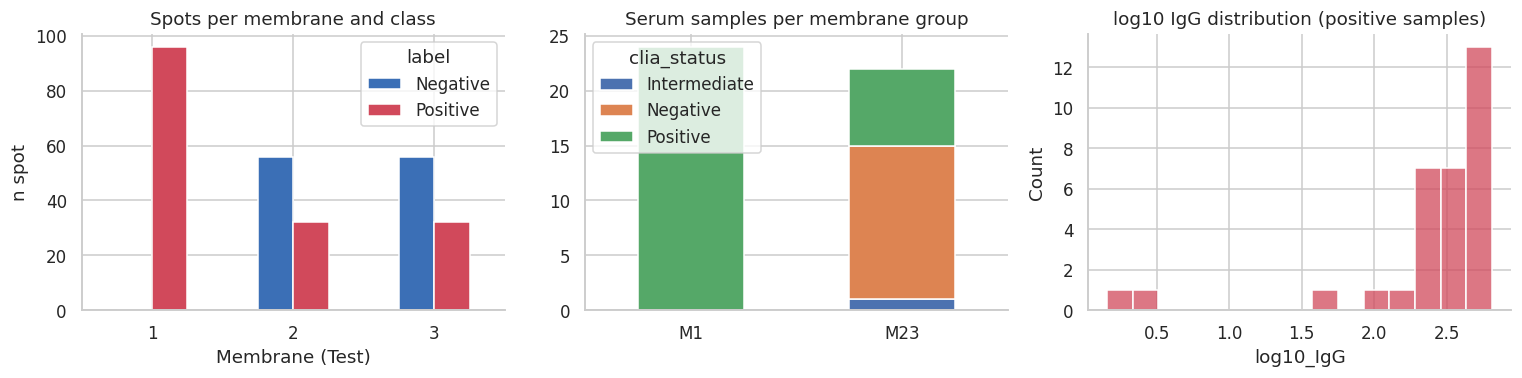

In [6]:
comp = IDX[IDX.lux==850].groupby(['membrane','label']).agg(spot=('spot_id','nunique'), samples=('sample_id','nunique')).unstack(fill_value=0)
print(comp)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
IDX[IDX.lux==850].groupby(['membrane','label']).size().unstack().plot.bar(ax=ax[0], rot=0, color=['#3b6fb6','#d1495b'])
ax[0].set_title('Spots per membrane and class'); ax[0].set_xlabel('Membrane (Test)'); ax[0].set_ylabel('n spot')
META.groupby(['membrane_grp','clia_status']).size().unstack(fill_value=0).plot.bar(ax=ax[1], rot=0, stacked=True)
ax[1].set_title('Serum samples per membrane group'); ax[1].set_xlabel('')
sns.histplot(META[META.y==1], x='log10_IgG', bins=15, ax=ax[2], color='#d1495b'); ax[2].set_title('log10 IgG distribution (positive samples)')
savefig('F01_composition')

### 3.2 Visual inspection & image size

load:   0%|          | 0/1360 [00:00<?, ?it/s]

      side_h  side_w
min    118.0   118.0
mean   189.4   189.4
max    216.0   216.0


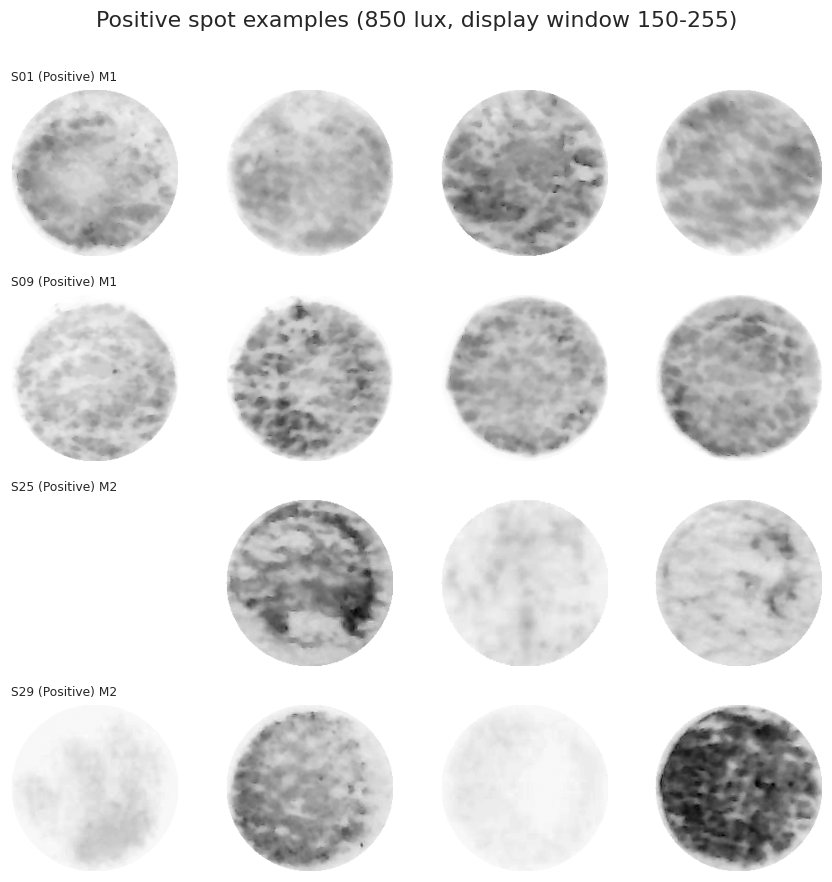

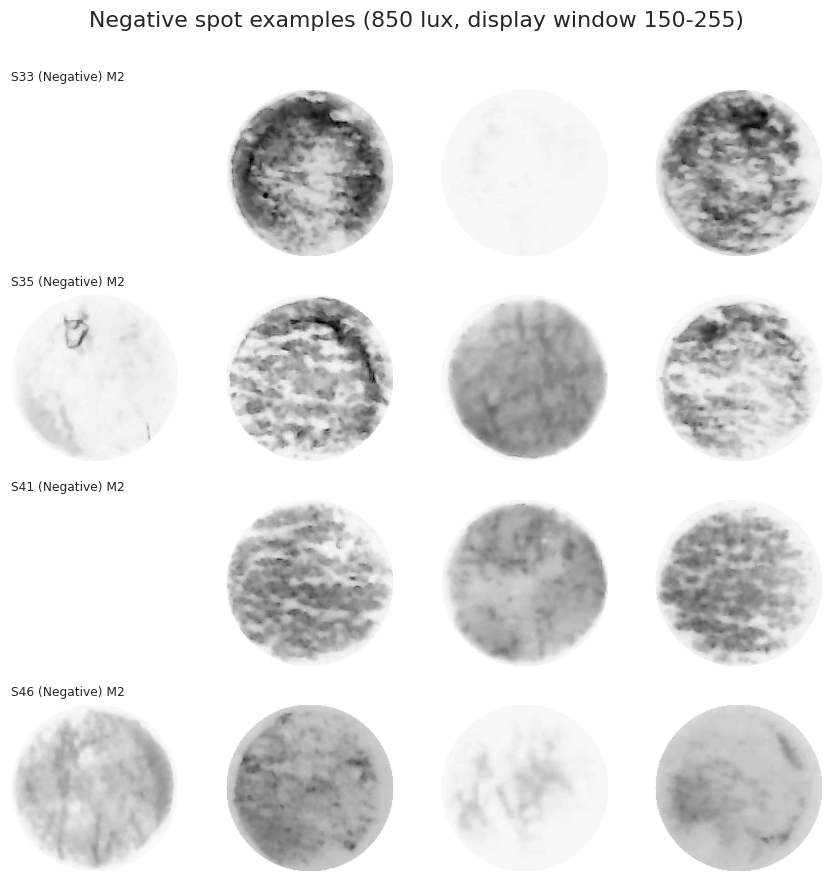

In [7]:
IMG = {}   # uint8 image cache
def load_img(p):
    if p not in IMG: IMG[p] = np.array(Image.open(p).convert('L'))
    return IMG[p]
for p in tqdm(IDX.path, desc='load'): load_img(p)
IDX['side_h'] = [IMG[p].shape[0] for p in IDX.path]; IDX['side_w'] = [IMG[p].shape[1] for p in IDX.path]
print(IDX[['side_h','side_w']].describe().loc[['min','mean','max']].round(1))

def montage(sample_ids, lux=850, membrane=None, title=''):
    fig, ax = plt.subplots(len(sample_ids), 4, figsize=(8, 2*len(sample_ids)))
    ax = np.atleast_2d(ax)
    for i, sid in enumerate(sample_ids):
        sub = IDX[(IDX.sample_id==sid)&(IDX.lux==lux)]
        if membrane: sub = sub[sub.membrane==membrane]
        sub = sub.sort_values(['row','col']).head(4)
        for j in range(4):
            a = ax[i, j]; a.axis('off')
            if j < len(sub):
                a.imshow(IMG[sub.iloc[j].path], cmap='gray', vmin=150, vmax=255)
                if j == 0: a.set_title(f"{sid} ({sub.iloc[j].label}) M{sub.iloc[j].membrane}", fontsize=8, loc='left')
    fig.suptitle(title, y=1.0); return fig
pos_ids = ['S01','S09','S25','S29']; neg_ids = ['S33','S35','S41','S46']
montage(pos_ids, 850, 2 if False else None, 'Positive spot examples (850 lux, display window 150-255)'); savefig('F02_montage_pos')
montage(neg_ids, 850, None, 'Negative spot examples (850 lux, display window 150-255)'); savefig('F03_montage_neg')

### 3.3 Artefact & *batch-effect* diagnostics (the core critique of a morphology-based approach)
Two questions: **(i)** does the crop size/shape alone already predict the class? **(ii)** do between-membrane (batch) differences rival between-class differences? Because Membrane 1 is entirely positive, the AUC on the full data can rise merely because of the *membrane*, not because of antibody binding. The fair comparator is the **MIX** subset (Membranes 2+3), in which both classes are on the same membrane with identical composition.

                n_spot  AUC_crop_side  AUC_mean_gray
subset                                              
ALL (M1+M2+M3)     272          0.759          0.597
MIX (M2+M3)        176          0.512          0.567


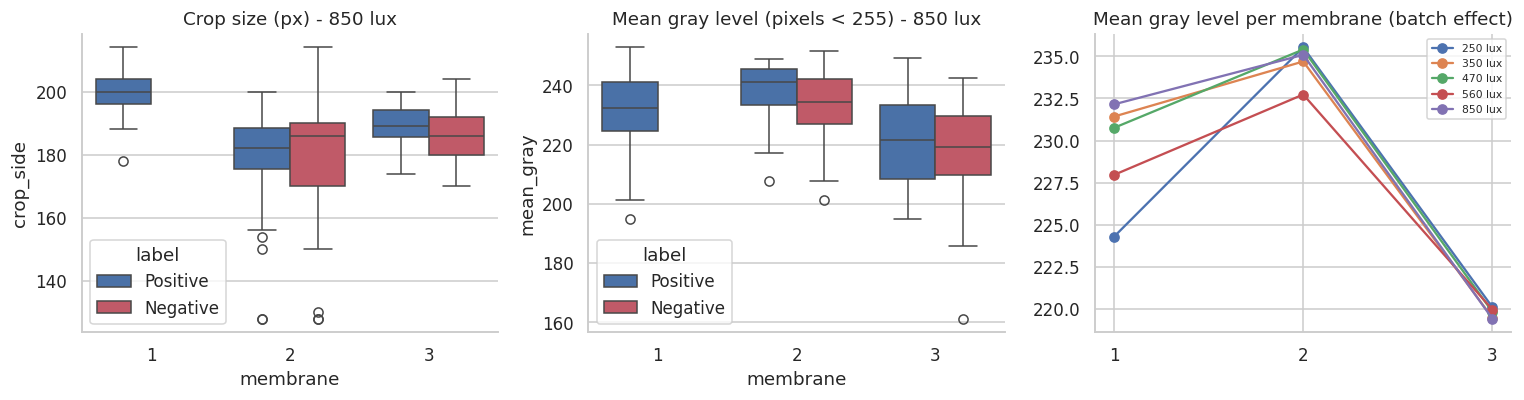

In [8]:
def auc_safe(y, s):
    y = np.asarray(y); s = np.asarray(s, float); ok = np.isfinite(s)
    return roc_auc_score(y[ok], s[ok]) if len(np.unique(y[ok])) == 2 else np.nan

D = IDX[IDX.lux==850].copy()
D['crop_side'] = D[['side_h','side_w']].max(axis=1)
D['mean_gray'] = [IMG[p][IMG[p] < 255].mean() if (IMG[p] < 255).any() else np.nan for p in D.path]
rows = []
for nm, sub in {'ALL (M1+M2+M3)': D, 'MIX (M2+M3)': D[D.membrane != 1]}.items():
    rows.append(dict(subset=nm, n_spot=len(sub), AUC_crop_side=auc_safe(sub.y, sub.crop_side),
                     AUC_mean_gray=auc_safe(sub.y, sub.mean_gray)))
diag = pd.DataFrame(rows).set_index('subset'); print(diag.round(3)); savetab(diag, 'T02_artifact_diagnostic_simple')

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
sns.boxplot(data=D, x='membrane', y='crop_side', hue='label', ax=ax[0], palette=['#3b6fb6','#d1495b']); ax[0].set_title('Crop size (px) - 850 lux')
sns.boxplot(data=D, x='membrane', y='mean_gray', hue='label', ax=ax[1], palette=['#3b6fb6','#d1495b']); ax[1].set_title('Mean gray level (pixels < 255) - 850 lux')
for lx in CFG['LUX_LEVELS']:
    s = IDX[(IDX.lux==lx)].copy(); s['mg'] = [IMG[p][IMG[p]<255].mean() if (IMG[p]<255).any() else np.nan for p in s.path]
    ax[2].plot([1,2,3], [s[s.membrane==m].mg.mean() for m in [1,2,3]], marker='o', label=f'{lx} lux')
ax[2].set_xticks([1,2,3]); ax[2].set_title('Mean gray level per membrane (batch effect)'); ax[2].legend(fontsize=7)
savefig('F04_artifact_batch_diagnostic')

### 3.4 Intensity distribution per lux level

              g_mean  g_std  nonwhite_frac
lux label                                 
250 Negative  225.91  11.72           0.74
    Positive  226.33  10.21           0.75
350 Negative  225.55  11.92           0.74
    Positive  230.24  10.12           0.75
470 Negative  225.51  11.99           0.73
    Positive  230.35  10.26           0.75
560 Negative  225.44  12.11           0.74
    Positive  227.57  10.53           0.76
850 Negative  225.44  11.88           0.74
    Positive  230.92  10.09           0.75


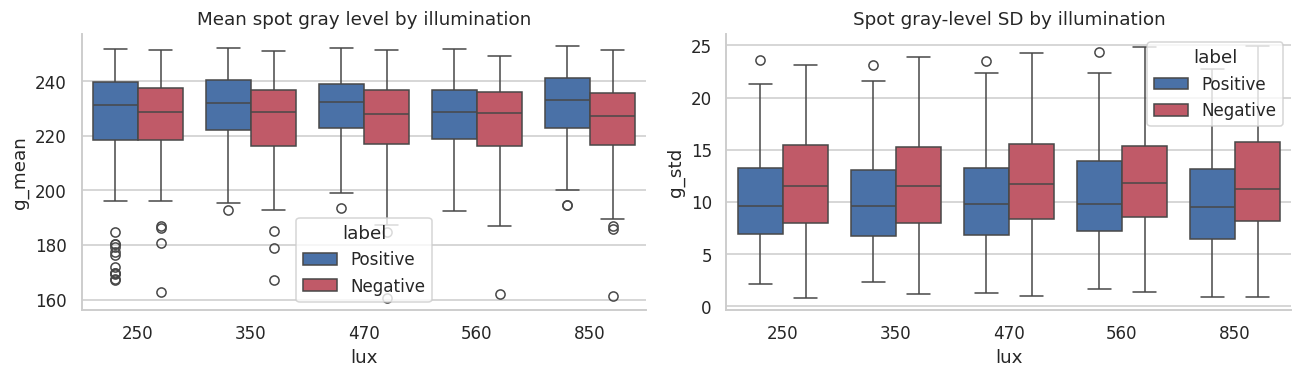

In [9]:
def spot_gray_stats(p):
    a = IMG[p]; v = a[a < 255]
    return (v.mean(), v.std(), (a < 255).mean()) if v.size else (np.nan, np.nan, 0.0)
st = np.array([spot_gray_stats(p) for p in IDX.path]); IDX['g_mean'], IDX['g_std'], IDX['nonwhite_frac'] = st.T
g = IDX.groupby(['lux','label'])[['g_mean','g_std','nonwhite_frac']].mean().round(2); print(g)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
sns.boxplot(data=IDX, x='lux', y='g_mean', hue='label', ax=ax[0], palette=['#3b6fb6','#d1495b']); ax[0].set_title('Mean spot gray level by illumination')
sns.boxplot(data=IDX, x='lux', y='g_std', hue='label', ax=ax[1], palette=['#3b6fb6','#d1495b']); ax[1].set_title('Spot gray-level SD by illumination')
savefig('F05_gray_by_lux')

## 4. Data cleansing (QC for acquisition failures only)
Unlike a feature-based filter, the screening does **not** use feature values (IQR/MAD) — that risks removing genuine biological variation and shifting the class distribution. Only images that are *technically invalid* are removed:
1. **Blank crop** — almost all pixels = 255 (segmentation/crop failed at that lux level);
2. **Mask too small** — non-white area < `MIN_AREA_PX` after *closing + fill-holes*;
3. **Truncated / non-round crop** — low solidity or a mask that massively touches the image border (sign of a truncated object);
4. Duplicate names/IDs and label consistency (already verified in §2).

In [10]:
def spot_mask(a):
    m = a < 255
    if m.sum() < 50: return None
    m = ndi.binary_closing(m, structure=morphology.disk(2))
    m = ndi.binary_fill_holes(m)
    lab, n = ndi.label(m)
    if n == 0: return None
    sz = ndi.sum(m, lab, range(1, n+1)); return lab == (1 + int(np.argmax(sz)))

def geometry(a, m):
    area = int(m.sum()); cy, cx = ndi.center_of_mass(m); R = math.sqrt(area / math.pi)
    rp = measure.regionprops(m.astype(np.uint8))[0]
    edge_touch = int(m[0].sum() + m[-1].sum() + m[:,0].sum() + m[:,-1].sum())
    return dict(area=area, cy=cy, cx=cx, R=R, perimeter=rp.perimeter, solidity=rp.solidity, eccentricity=rp.eccentricity,
                extent=rp.extent, edge_touch=edge_touch)

MASK, GEO = {}, {}
qc = []
for r in tqdm(IDX.itertuples(), total=len(IDX), desc='QC'):
    a = IMG[r.path]; m = spot_mask(a)
    if m is None: qc.append(dict(image_id=r.image_id, valid=False, reason='blank')); continue
    gm = geometry(a, m); MASK[r.image_id] = m; GEO[r.image_id] = gm
    reason = 'ok'
    if gm['area'] < CFG['MIN_AREA_PX']: reason = 'small_mask'
    elif gm['solidity'] < 0.90 or gm['edge_touch'] > 0.25 * 2 * math.pi * gm['R']: reason = 'truncated'
    qc.append(dict(image_id=r.image_id, valid=(reason == 'ok'), reason=reason, **gm))
QC = pd.DataFrame(qc); IDX = IDX.merge(QC, on='image_id', how='left'); IDX['valid'] = IDX.valid.fillna(False).astype(bool)
print(IDX.groupby(['lux'])['valid'].agg(['sum','count']).T)
print(pd.crosstab(IDX.reason.fillna('blank'), [IDX.membrane]))
savetab(IDX.drop(columns='path'), 'T03_qc_flags', index=False)

QC:   0%|          | 0/1360 [00:00<?, ?it/s]

lux    250  350  470  560  850
sum    258  259  259  262  258
count  272  272  272  272  272
membrane     1    2    3
reason                  
blank        5   55    0
ok         471  385  440
truncated    4    0    0


,file,membrane,col,row,label_file,lux,membrane_grp,block_row,block_col,sample_id,...,reason,area,cy,cx,R,perimeter,solidity,eccentricity,extent,edge_touch
0,10_A_Positive_250.png,1,10,A,Positive,250,M1,A-B,9-10,S09,...,ok,34419.0,104.877306,104.877306,104.670473,686.440692,0.995143,0.003315,0.811080,0.0
1,10_A_Positive_350.png,1,10,A,Positive,350,M1,A-B,9-10,S09,...,ok,35063.0,105.878390,105.878390,105.645159,692.097546,0.995684,0.003256,0.810443,0.0
2,10_A_Positive_470.png,1,10,A,Positive,470,M1,A-B,9-10,S09,...,ok,33115.0,102.874951,102.874951,102.668554,672.783838,0.995431,0.003445,0.811563,0.0
3,10_A_Positive_560.png,1,10,A,Positive,560,M1,A-B,9-10,S09,...,ok,35063.0,105.878390,105.878390,105.645159,692.097546,0.995684,0.003256,0.810443,0.0
4,10_A_Positive_850.png,1,10,A,Positive,850,M1,A-B,9-10,S09,...,ok,33021.0,103.125435,102.762484,102.522733,675.269119,0.994040,0.095238,0.809259,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1355,9_F_Negative_250.png,3,9,F,Negative,250,M23,E-F,9-10,S45,...,ok,25259.0,89.871095,89.871095,89.667103,587.529004,0.994958,0.004066,0.815438,0.0
1356,9_F_Negative_350.png,3,9,F,Negative,350,M23,E-F,9-10,S45,...,ok,25811.0,90.872419,90.872419,90.641582,593.185858,0.995065,0.003981,0.814638,0.0
1357,9_F_Negative_470.png,3,9,F,Negative,470,M23,E-F,9-10,S45,...,ok,26375.0,91.866919,91.866919,91.626542,601.185858,0.994570,0.004108,0.814043,0.0
1358,9_F_Negative_560.png,3,9,F,Negative,560,M23,E-F,9-10,S45,...,ok,25811.0,90.872419,90.872419,90.641582,593.185858,0.995065,0.003981,0.814638,0.0


Invalid images: 64 (4.7%)
lux                250  350  470  560  850
membrane label                            
1        Positive    2    2    1    1    3
2        Negative    7    7    8    6    7
         Positive    5    4    4    3    4

Spots valid at all 5 lux levels: 255 | 1-4 lux: 9 | 0 lux: 8
Fisher exact (validity vs class, MIX): 1.0
{'neg': 14, 'pos': 32} <- samples remaining


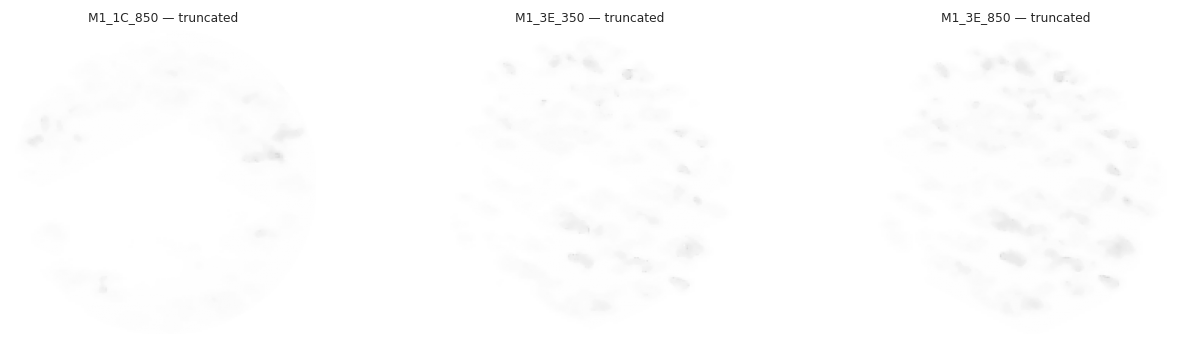

In [11]:
# Impact of QC on data composition & spots that drop out at only some lux levels
inv = IDX[~IDX.valid]
print('Invalid images:', len(inv), f'({len(inv)/len(IDX):.1%})')
print(inv.groupby(['membrane','label','lux']).size().unstack(fill_value=0))
spot_valid_lux = IDX.groupby('spot_id').valid.sum()
print('\nSpots valid at all 5 lux levels:', int((spot_valid_lux==5).sum()), '| 1-4 lux:', int(((spot_valid_lux>0)&(spot_valid_lux<5)).sum()), '| 0 lux:', int((spot_valid_lux==0).sum()))
# Are crop failures randomly distributed with respect to class? (Fisher test: validity vs class, MIX membranes)
mix = IDX[IDX.membrane != 1]
print('Fisher exact (validity vs class, MIX):', round(stats.fisher_exact(pd.crosstab(mix.valid, mix.y))[1], 4))
# Samples remaining per class after QC (at least 1 valid spot)
VAL = IDX[IDX.valid].copy()
print(VAL.groupby('y').sample_id.nunique().rename({0:'neg',1:'pos'}).to_dict(), '<- samples remaining')
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
bl = inv.head(3)
for a_, r in zip(ax, bl.itertuples()):
    a_.imshow(IMG[r.path], cmap='gray', vmin=0, vmax=255); a_.set_title(f'{r.image_id} — {r.reason}', fontsize=8); a_.axis('off')
savefig('F06_invalid_examples')

## 5. Physical pre-processing: inner ROI & Optical Density
**Why an inner ROI?** The spot contour is shaped by circular segmentation/cropping and by pressing on the membrane; the spot edge (*rim*) is the zone most affected by artefacts (ring effect, edge fading, 5% padding). All quantification features are computed **only inside a concentric disk with a radius of 85% of the equivalent radius** (`ROI_FRAC`), so that contour size and shape do not enter the features.

**Optical Density (Beer–Lambert).** For pixel intensity *I* and white reference *I₀* = 255:  OD = −log₁₀(*I*/*I₀*). OD is proportional to the amount of deposited chromogen (linear range), unlike raw gray values, which are non-linear.

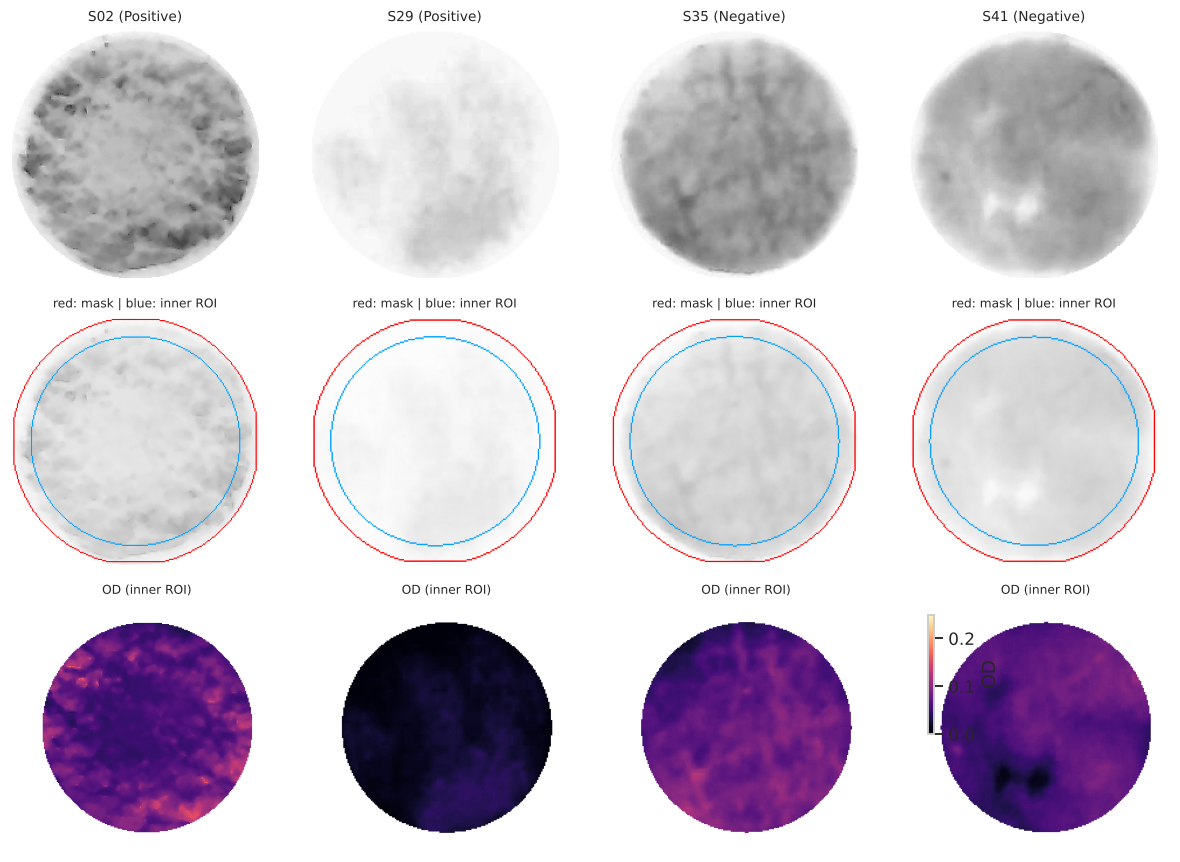

In [12]:
I0 = 255.0
def to_od(a): return -np.log10(np.clip(a.astype(np.float32), 1, 255) / I0)

def roi_masks(image_id, a=None):
    m = MASK[image_id]; g = GEO[image_id]
    yy, xx = np.ogrid[:m.shape[0], :m.shape[1]]
    d = np.hypot(yy - g['cy'], xx - g['cx']) / g['R']            # distance normalised by radius (0..1 = spot edge)
    roi = m & (d <= CFG['ROI_FRAC'])
    return m, roi, d

# Visual: mask, inner ROI and OD map for positive vs negative examples
ex = [VAL[(VAL.sample_id==s)&(VAL.lux==850)].iloc[0] for s in ['S02','S29','S35','S41']]
fig, ax = plt.subplots(3, 4, figsize=(11, 8))
for j, r in enumerate(ex):
    a = IMG[r.path]; m, roi, d = roi_masks(r.image_id)
    ax[0, j].imshow(a, cmap='gray', vmin=150, vmax=255); ax[0, j].set_title(f'{r.sample_id} ({r.label})', fontsize=9)
    ov = np.dstack([a]*3).astype(np.uint8); edge = m ^ ndi.binary_erosion(m); edge2 = roi ^ ndi.binary_erosion(roi)
    ov[edge] = [255, 0, 0]; ov[edge2] = [0, 160, 255]; ax[1, j].imshow(ov); ax[1, j].set_title('red: mask | blue: inner ROI', fontsize=8)
    od = np.where(roi, to_od(a), np.nan); im = ax[2, j].imshow(od, cmap='magma', vmin=0, vmax=0.25); ax[2, j].set_title('OD (inner ROI)', fontsize=8)
    for k in range(3): ax[k, j].axis('off')
fig.colorbar(im, ax=ax[2, :], shrink=0.6, label='OD'); savefig('F07_roi_od_examples')

## 6. Quantification methods (Pipeline A — feature stage)
Six **ROI-content-based** feature families (rotation/shape invariant) plus two **controls** that are deliberately designed to measure artefacts:

| Code | Family | Content | Physical/statistical basis |
|---|---|---|---|
| **Q1** | Absolute OD densitometry | mean, median, SD, MAD, 5/25/75/95th percentiles, skewness, kurtosis | Beer–Lambert; amount of chromogen |
| **Q2** | Local-background-corrected relative OD | OD relative to the ROI's own 90th percentile, plane-fit residual, core–inner-rim contrast, CV, entropy | cancels multiplicative illumination effects & background gradients |
| **Q3** | Radial profile | mean OD in 6 concentric rings (0–0.85 R) + slope & curvature | spatial signal distribution independent of the contour |
| **Q4** | Rotation-invariant texture | GLCM (mean over 4 angles; distances 1 & 2), LBP-uniform (P=8, R=1), multi-scale DoG energy | granularity of precipitate/membrane fibres |
| **Q5** | OD histogram | 16 bins with fixed edges (global, label-free range) | fingerprint of the intensity distribution |
| **Q6** | Radial power spectrum | 8 spatial-frequency bands (FFT, radially averaged) | structure scale, rotation invariance |
| CTRL-Shape | **Artefact control** | area, radius, perimeter, circularity, eccentricity, solidity, extent, crop side | *what a morphology-based approach uses* |
| CTRL-Batch | **Batch control** | membrane indicator | batch confound |

In [13]:
def _moments(v):
    return dict(mean=float(v.mean()), median=float(np.median(v)), std=float(v.std()), mad=float(stats.median_abs_deviation(v, scale='normal')),
                p05=float(np.percentile(v, 5)), p25=float(np.percentile(v, 25)), p75=float(np.percentile(v, 75)), p95=float(np.percentile(v, 95)),
                skew=float(stats.skew(v)), kurt=float(stats.kurtosis(v)))

def q1_densitometry(od, roi):
    return {f'Q1__{k}': x for k, x in _moments(od[roi]).items()}

def q2_relative(od, a, roi, d):
    v_int = a[roi].astype(np.float32); ref = np.percentile(v_int, 90)                    # local-background reference (brightest pixels in the ROI)
    odr = -np.log10(np.clip(a.astype(np.float32), 1, 255) / max(ref, 1.0)); v = odr[roi]
    # plane residual: ODr ≈ b0 + b1*x + b2*y (illumination/membrane gradient)
    yy, xx = np.nonzero(roi); A = np.c_[np.ones(len(yy)), xx - xx.mean(), yy - yy.mean()]
    coef, *_ = np.linalg.lstsq(A, v, rcond=None); res = v - A @ coef
    core = roi & (d <= 0.45); ring = roi & (d > 0.45)
    h, _ = np.histogram(v, bins=24); p = h / max(h.sum(), 1); ent = -np.sum(p[p > 0] * np.log2(p[p > 0]))
    return {'Q2__od_rel_mean': v.mean(), 'Q2__od_rel_std': v.std(), 'Q2__od_rel_p95': np.percentile(v, 95), 'Q2__od_rel_p50': np.percentile(v, 50),
            'Q2__cv': v.std() / (np.abs(v.mean()) + 1e-6), 'Q2__plane_res_std': res.std(), 'Q2__plane_grad': float(np.hypot(coef[1], coef[2])),
            'Q2__core_minus_ring': float(odr[core].mean() - odr[ring].mean()) if core.any() and ring.any() else np.nan,
            'Q2__entropy': ent, 'Q2__ref_I90': ref}

RAD_EDGES = np.linspace(0, CFG['ROI_FRAC'], 7)
def q3_radial(od, m, d):
    prof = []
    for i in range(6):
        sel = m & (d >= RAD_EDGES[i]) & (d < RAD_EDGES[i+1]); prof.append(od[sel].mean() if sel.any() else np.nan)
    prof = np.array(prof); x = np.arange(6)
    ok = np.isfinite(prof)
    slope = np.polyfit(x[ok], prof[ok], 1)[0] if ok.sum() > 2 else np.nan
    curv = np.polyfit(x[ok], prof[ok], 2)[0] if ok.sum() > 3 else np.nan
    out = {f'Q3__ring{i+1}': prof[i] for i in range(6)}; out.update({'Q3__slope': slope, 'Q3__curv': curv, 'Q3__center_to_edge': prof[0] - prof[-1]}); return out

def _glcm_feats(img_q, valid, levels, tag):
    # img_q: int (0..levels-1); outside the ROI = levels (extra level, discarded)
    q = np.where(valid, img_q, levels).astype(np.uint8)
    out = {}
    for dist in (1, 2):
        G = feature.graycomatrix(q, [dist], [0, np.pi/4, np.pi/2, 3*np.pi/4], levels=levels+1, symmetric=True, normed=False)[:levels, :levels, 0, :]
        Gs = G.astype(np.float64); Gs = Gs / np.maximum(Gs.sum(axis=(0, 1), keepdims=True), 1)
        i, j = np.meshgrid(np.arange(levels), np.arange(levels), indexing='ij')
        con = (Gs * (i - j)[:, :, None]**2).sum((0, 1)); dis = (Gs * np.abs(i - j)[:, :, None]).sum((0, 1))
        hom = (Gs / (1 + (i - j)[:, :, None]**2)).sum((0, 1)); asm = (Gs**2).sum((0, 1))
        mu_i = (Gs * i[:, :, None]).sum((0, 1)); mu_j = (Gs * j[:, :, None]).sum((0, 1))
        si = np.sqrt((Gs * (i[:, :, None] - mu_i)**2).sum((0, 1))); sj = np.sqrt((Gs * (j[:, :, None] - mu_j)**2).sum((0, 1)))
        cor = (Gs * (i[:, :, None] - mu_i) * (j[:, :, None] - mu_j)).sum((0, 1)) / np.maximum(si * sj, 1e-9)
        ent = -(Gs * np.log2(np.where(Gs > 0, Gs, 1))).sum((0, 1))
        for nm, val in dict(contrast=con, dissim=dis, homog=hom, asm=asm, corr=cor, entropy=ent).items():
            out[f'{tag}__glcm_{nm}_d{dist}'] = float(np.mean(val))          # average of 4 directions -> rotation invariance
    return out

def q4_texture(od, roi):
    ys, xs = np.nonzero(roi); y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    sub = od[y0:y1, x0:x1]; r = roi[y0:y1, x0:x1]
    v = sub[r]; lo, hi = np.percentile(v, 1), np.percentile(v, 99)
    q = np.clip((sub - lo) / max(hi - lo, 1e-6), 0, 1); q = np.minimum((q * 32).astype(int), 31)          # per-image normalisation: pure texture
    out = _glcm_feats(q, r, 32, 'Q4')
    filled = np.where(r, sub, v.mean())
    lbp = feature.local_binary_pattern(filled, 8, 1, method='uniform'); inner = ndi.binary_erosion(r, iterations=2)
    hist = np.bincount(lbp[inner].astype(int), minlength=10)[:10].astype(float); hist /= max(hist.sum(), 1)
    out.update({f'Q4__lbp{k}': hist[k] for k in range(10)})
    sig = [1, 2, 4, 8]; G = [ndi.gaussian_filter(filled, s) for s in sig]
    for k in range(3): out[f'Q4__dog{k+1}_energy'] = float((G[k] - G[k+1])[inner].std())
    out['Q4__lowfreq_std'] = float(G[3][inner].std()); return out

def q5_histogram(od, roi, edges):
    h, _ = np.histogram(od[roi], bins=edges); h = h / max(h.sum(), 1); return {f'Q5__bin{k:02d}': h[k] for k in range(len(h))}

def q6_spectrum(od, roi, nb=8, S=96):
    ys, xs = np.nonzero(roi); y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    sub = od[y0:y1, x0:x1].copy(); r = roi[y0:y1, x0:x1]
    sub = np.where(r, sub - sub[r].mean(), 0.0); sub = resize(sub, (S, S), order=1, anti_aliasing=True)
    win = np.hanning(S)[:, None] * np.hanning(S)[None, :]
    P = np.abs(np.fft.fftshift(np.fft.fft2(sub * win)))**2
    yy, xx = np.indices(P.shape); rr = np.hypot(yy - S/2, xx - S/2); edges = np.linspace(1, S/2, nb + 1)
    pw = np.array([P[(rr >= edges[i]) & (rr < edges[i+1])].mean() for i in range(nb)]); pw = pw / max(pw.sum(), 1e-12)
    return {f'Q6__band{i+1}': pw[i] for i in range(nb)}

def ctrl_shape(g, a):
    area, per = g['area'], g['perimeter']
    return {'CS__area': area, 'CS__R': g['R'], 'CS__perimeter': per, 'CS__circularity': 4*math.pi*area/max(per**2, 1e-6), 'CS__eccentricity': g['eccentricity'],
            'CS__solidity': g['solidity'], 'CS__extent': g['extent'], 'CS__crop_side': float(max(a.shape))}

# --- global edges for the OD histogram (label-free): 0.5–99.5th percentile over all ROI pixels ---
_samp = []
for r in VAL.itertuples():
    m, roi, d = roi_masks(r.image_id); _samp.append(to_od(IMG[r.path])[roi][::7])
_samp = np.concatenate(_samp); OD_EDGES = np.linspace(np.percentile(_samp, 0.5), np.percentile(_samp, 99.5), 17)
print('OD histogram range:', OD_EDGES[[0, -1]].round(4))

def extract_all(r):
    a = IMG[r.path]; m, roi, d = roi_masks(r.image_id); od = to_od(a)
    f = {'image_id': r.image_id}
    f.update(q1_densitometry(od, roi)); f.update(q2_relative(od, a, roi, d)); f.update(q3_radial(od, m, d))
    f.update(q4_texture(od, roi)); f.update(q5_histogram(od, roi, OD_EDGES)); f.update(q6_spectrum(od, roi)); f.update(ctrl_shape(GEO[r.image_id], a))
    return f

t0 = time.time()
FEATS = pd.DataFrame(Parallel(n_jobs=CFG['N_JOBS'], prefer='threads')(delayed(extract_all)(r) for r in tqdm(list(VAL.itertuples()), desc='features')))
FEATS = FEATS.set_index('image_id')
print(f'Feature extraction done: {FEATS.shape} in {time.time()-t0:.1f}s | total NaN: {int(FEATS.isna().sum().sum())}')
GROUPS = OrderedDict([('Q1_Densitometry', [c for c in FEATS if c.startswith('Q1__')]), ('Q2_RelativeOD', [c for c in FEATS if c.startswith('Q2__')]),
                      ('Q3_Radial', [c for c in FEATS if c.startswith('Q3__')]), ('Q4_Texture', [c for c in FEATS if c.startswith('Q4__')]),
                      ('Q5_Histogram', [c for c in FEATS if c.startswith('Q5__')]), ('Q6_Spectrum', [c for c in FEATS if c.startswith('Q6__')]),
                      ('CTRL_Shape', [c for c in FEATS if c.startswith('CS__')])])
print({k: len(v) for k, v in GROUPS.items()})
FEATS.to_csv(os.path.join(OUT_DIR, 'tables', 'T04_features_raw.csv'))

OD histogram range: [0.0034 0.2024]


features:   0%|          | 0/1296 [00:00<?, ?it/s]

Feature extraction done: (1296, 87) in 35.2s | total NaN: 0
{'Q1_Densitometry': 10, 'Q2_RelativeOD': 10, 'Q3_Radial': 9, 'Q4_Texture': 26, 'Q5_Histogram': 16, 'Q6_Spectrum': 8, 'CTRL_Shape': 8}


## 7. Between-membrane normalisation (*batch correction*, label-free)
The difference in mean background between membranes (Membrane 2 vs 3 ≈ 15–17 gray levels) is larger than the between-class difference. Two versions of the feature table are compared:

* **`abs`** — physical values as they are (absolute OD);
* **`mem`** — per-(membrane × lux × feature) *robust z-score*: (x − median) / (1.4826·MAD), using **all spots on that membrane without using labels**. In MIX the class composition of M2 and M3 is identical (8 positive : 14 negative), so this correction does not shift the classes; in ALL, Membrane 1 contains only positives → the correction removes part of the M1 signal (conservative). Shape features are not normalised (control).

The choice between `abs` and `mem` is made in §10 through a controlled screening; both versions are reported.

In [14]:
META_IMG = VAL.set_index('image_id')[['sample_id','spot_id','membrane','lux','y','label','membrane_grp','sample_no','IgM','IgG','log10_IgG','clia_status']]
FE = META_IMG.join(FEATS.astype('float64'), how='inner')
NONSHAPE = [c for k, v in GROUPS.items() if k != 'CTRL_Shape' for c in v]

def robust_z_fast(df, cols, by=('membrane','lux')):
    out = df.copy()
    for _, idx in df.groupby(list(by)).groups.items():
        sub = df.loc[idx, cols]; med = sub.median(); mad = (sub - med).abs().median() * 1.4826
        out.loc[idx, cols] = (sub - med) / mad.replace(0, np.nan)
    return out
FE_abs = FE.copy(); FE_mem = robust_z_fast(FE, NONSHAPE)
FE_mem[NONSHAPE] = FE_mem[NONSHAPE].replace([np.inf, -np.inf], np.nan).clip(-8, 8)
VARIANTS = {'abs': FE_abs, 'mem': FE_mem}
print({k: v.shape for k, v in VARIANTS.items()})

{'abs': (1296, 99), 'mem': (1296, 99)}


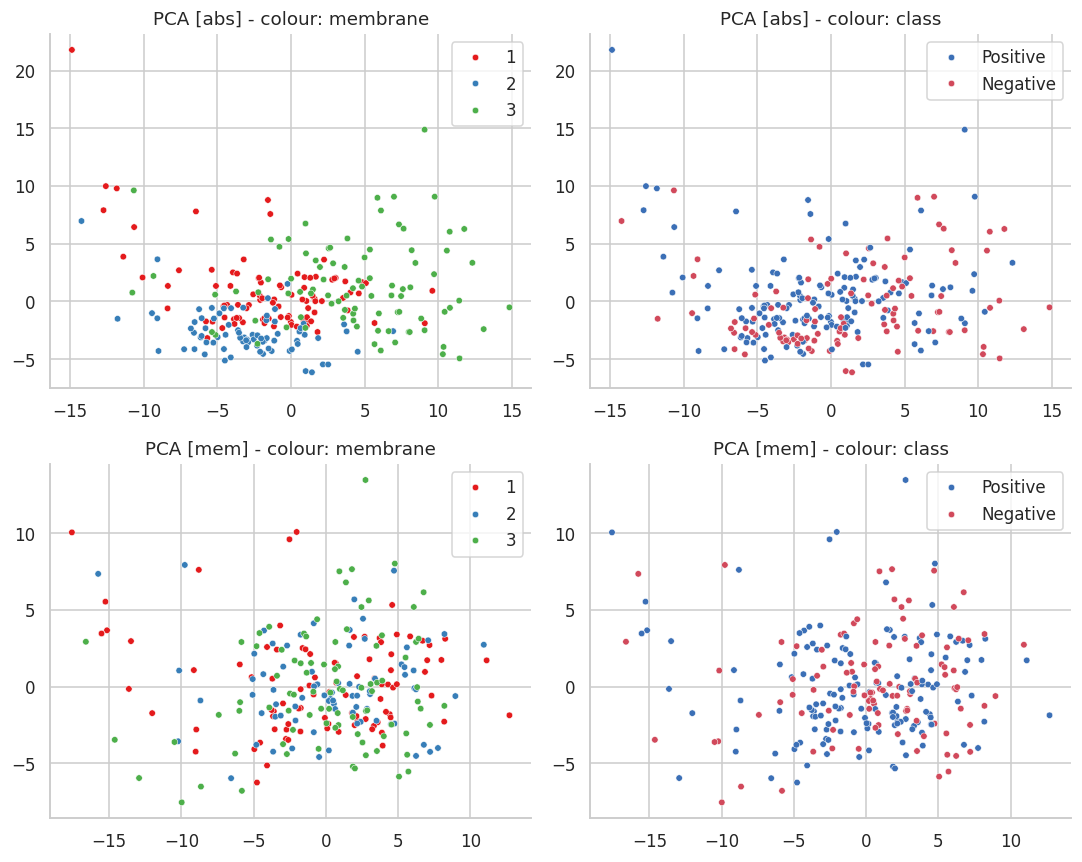

variant  silhouette_membrane  silhouette_class
    abs                0.055             0.035
    mem                0.005             0.017


,variant,silhouette_membrane,silhouette_class
0,abs,0.055465,0.035253
1,mem,0.005478,0.017211


In [15]:
# Batch diagnostic: how strongly membrane vs class is encoded in feature space (850 lux), before/after normalisation
def batch_diag(df, cols, lux=850):
    d = df[df.lux == lux]; X = StandardScaler().fit_transform(SimpleImputer(strategy='median').fit_transform(d[cols]))
    pc = PCA(n_components=2).fit_transform(X)
    return d, pc, silhouette_score(X, d.membrane), (silhouette_score(X, d.y) if d.y.nunique() > 1 else np.nan)
fig, ax = plt.subplots(2, 2, figsize=(10, 8)); res = []
for i, (nm, df) in enumerate(VARIANTS.items()):
    d, pc, s_mem, s_cls = batch_diag(df, NONSHAPE); res.append(dict(variant=nm, silhouette_membrane=s_mem, silhouette_class=s_cls))
    sns.scatterplot(x=pc[:,0], y=pc[:,1], hue=d.membrane.astype(str).values, ax=ax[i,0], s=18, palette='Set1'); ax[i,0].set_title(f'PCA [{nm}] - colour: membrane')
    sns.scatterplot(x=pc[:,0], y=pc[:,1], hue=d.label.values, ax=ax[i,1], s=18, palette=['#3b6fb6','#d1495b']); ax[i,1].set_title(f'PCA [{nm}] - colour: class')
savefig('F08_pca_batch'); print(pd.DataFrame(res).round(3).to_string(index=False)); savetab(pd.DataFrame(res), 'T05_batch_silhouette', index=False)

## 8. Artefact-free univariate analysis (sample level, n = 46)
Replicates of the same serum are **not independent**; therefore the univariate tests use the **per-sample median** (spots × membranes → 1 value per sample per lux level). Mann–Whitney U test, **Cliff's δ** effect size, univariate AUC, and **Benjamini–Hochberg (FDR)** correction across the whole feature family. In the **MIX** protocol (M2+M3) comparisons are made only within the same membrane.

In [16]:
def cliffs_delta(a, b):
    a, b = np.asarray(a), np.asarray(b); u = stats.mannwhitneyu(a, b, alternative='two-sided').statistic; return 2 * u / (len(a) * len(b)) - 1
def bh_fdr(p):
    p = np.asarray(p, float); n = np.sum(np.isfinite(p)); o = np.argsort(np.where(np.isfinite(p), p, np.inf)); q = np.full_like(p, np.nan)
    ranked = p[o] * n / (np.arange(len(p)) + 1); ranked = np.minimum.accumulate(ranked[::-1])[::-1]; q[o] = np.minimum(ranked, 1); return q

def sample_level(df, cols, protocol):
    d = df if protocol == 'ALL' else df[df.membrane != 1]
    return d.groupby(['sample_id','y'])[cols].median().reset_index()

def univariate(df, protocol, lux, cols):
    s = sample_level(df[df.lux == lux], cols, protocol); pos, neg = s[s.y == 1], s[s.y == 0]; rows = []
    for c in cols:
        a, b = pos[c].dropna(), neg[c].dropna()
        if len(a) < 3 or len(b) < 3 or (a.nunique() + b.nunique()) < 3: continue
        p = stats.mannwhitneyu(a, b, alternative='two-sided').pvalue
        rows.append(dict(feature=c, family=c.split('__')[0], n_pos=len(a), n_neg=len(b), AUC=auc_safe(s.y, s[c]), cliffs_delta=cliffs_delta(a, b), p=p))
    r = pd.DataFrame(rows); r['q_BH'] = bh_fdr(r.p.values); r['AUC_dir'] = np.maximum(r.AUC, 1 - r.AUC)
    return r.sort_values('p').reset_index(drop=True)

UNI = {}
for prot in ['ALL', 'MIX']:
    for vn in ['abs', 'mem']:
        UNI[(prot, vn)] = univariate(VARIANTS[vn], prot, 850, NONSHAPE + GROUPS['CTRL_Shape'])
for k, r in UNI.items():
    print(f'\n=== {k}: top 8 features (850 lux) ===')
    print(r.head(8)[['feature','AUC','cliffs_delta','p','q_BH']].round(4).to_string(index=False))
    print('features with q<0.05:', int((r.q_BH < 0.05).sum()), '| families:', r[r.q_BH < 0.05].family.value_counts().to_dict())
    savetab(r, f'T06_univariate_{k[0]}_{k[1]}', index=False)


=== ('ALL', 'abs'): top 8 features (850 lux) ===
        feature    AUC  cliffs_delta      p   q_BH
  CS__perimeter 0.8850        0.7701 0.0000 0.0015
     CS__extent 0.1172       -0.7656 0.0000 0.0015
  CS__crop_side 0.8728        0.7455 0.0001 0.0015
       Q4__lbp6 0.1339       -0.7321 0.0001 0.0015
Q4__glcm_asm_d1 0.8616        0.7232 0.0001 0.0015
Q4__glcm_asm_d2 0.8594        0.7188 0.0001 0.0015
Q2__od_rel_mean 0.1451       -0.7098 0.0002 0.0015
 Q2__od_rel_p50 0.1473       -0.7054 0.0002 0.0015
features with q<0.05: 31 | families: {'Q4': 13, 'Q2': 7, 'CS': 6, 'Q1': 2, 'Q6': 2, 'Q3': 1}

=== ('ALL', 'mem'): top 8 features (850 lux) ===
        feature    AUC  cliffs_delta      p   q_BH
  CS__perimeter 0.8850        0.7701 0.0000 0.0019
     CS__extent 0.1172       -0.7656 0.0000 0.0019
  CS__crop_side 0.8728        0.7455 0.0001 0.0020
          CS__R 0.8504        0.7009 0.0002 0.0032
       CS__area 0.8504        0.7009 0.0002 0.0032
CS__circularity 0.1607       -0.6786 0.000

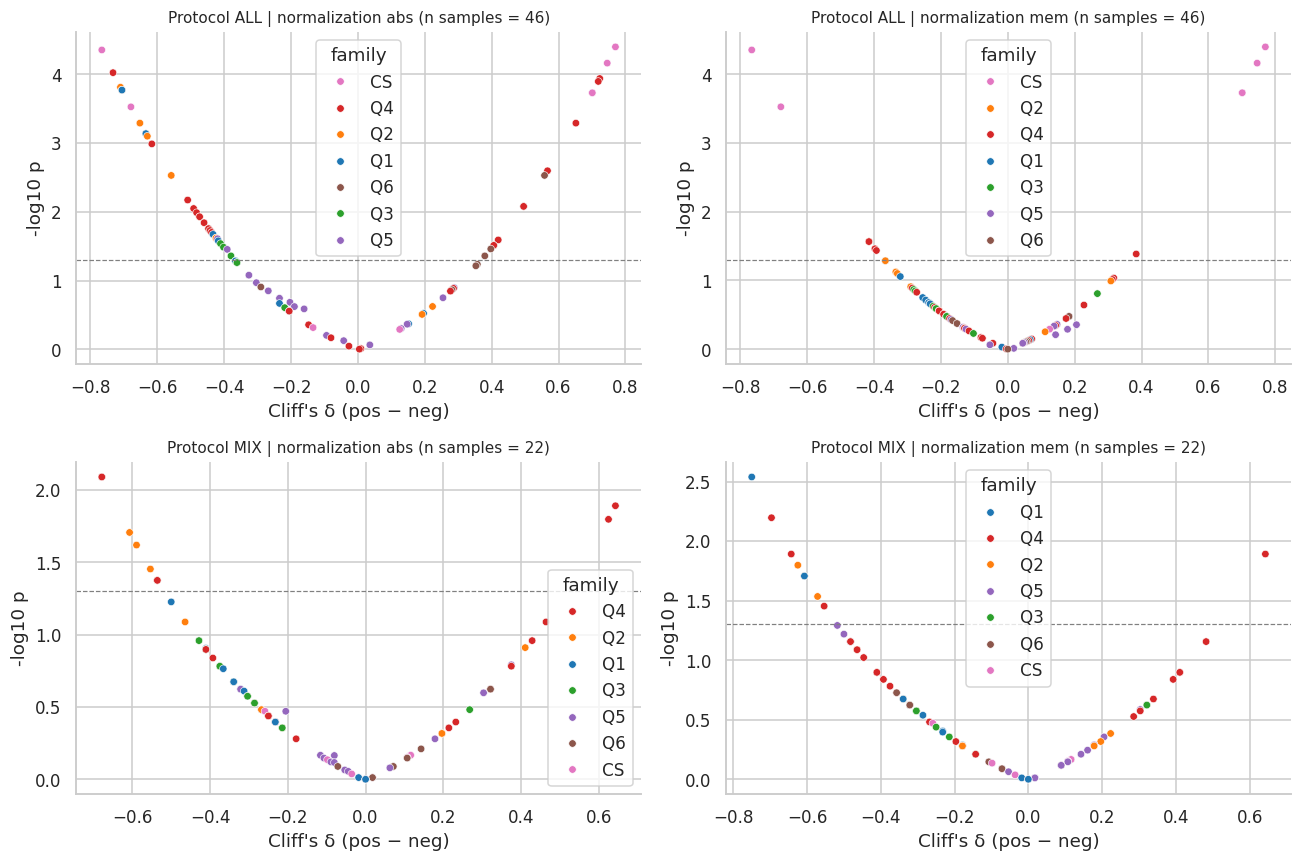

 lux protocol  n_p05  top10_AUCdir            best
 250      ALL      2         0.680 Q4__dog2_energy
 250      MIX     15         0.821 Q4__dog2_energy
 350      ALL      2         0.668 Q4__dog2_energy
 350      MIX     10         0.824 Q4__dog2_energy
 470      ALL     10         0.707 Q4__dog2_energy
 470      MIX     18         0.859       Q5__bin06
 560      ALL      5         0.688 Q4__dog2_energy
 560      MIX     12         0.818 Q4__dog2_energy
 850      ALL      5         0.686  Q2__od_rel_p95
 850      MIX     10         0.815         Q1__mad


,lux,protocol,n_p05,top10_AUCdir,best
0,250,ALL,2,0.680357,Q4__dog2_energy
1,250,MIX,15,0.821429,Q4__dog2_energy
2,350,ALL,2,0.668080,Q4__dog2_energy
3,350,MIX,10,0.824107,Q4__dog2_energy
4,470,ALL,10,0.707366,Q4__dog2_energy
5,470,MIX,18,0.859375,Q5__bin06
6,560,ALL,5,0.687723,Q4__dog2_energy
7,560,MIX,12,0.817857,Q4__dog2_energy
8,850,ALL,5,0.686161,Q2__od_rel_p95
9,850,MIX,10,0.815179,Q1__mad


In [17]:
# Volcano-like: directed AUC vs -log10 p, coloured by feature family (shape = artefact control)
fig, ax = plt.subplots(2, 2, figsize=(12, 8)); pal = dict(zip(['Q1','Q2','Q3','Q4','Q5','Q6','CS'], sns.color_palette('tab10', 7)))
for a_, (k, r) in zip(ax.ravel(), UNI.items()):
    sns.scatterplot(data=r, x='cliffs_delta', y=-np.log10(r.p), hue='family', palette=pal, ax=a_, s=24)
    a_.axhline(-np.log10(0.05), ls='--', c='gray', lw=0.8); a_.set_title(f'Protocol {k[0]} | normalization {k[1]} (n samples = {int(r.n_pos[0]+r.n_neg[0])})', fontsize=10)
    a_.set_xlabel("Cliff's δ (pos − neg)"); a_.set_ylabel('-log10 p')
savefig('F09_univariate_volcano')
# Which lux level is most informative univariately? (number of features with p<0.05 and median directed AUC of the top 10) — on protocol MIX/mem
rows = []
for lx in CFG['LUX_LEVELS']:
    for prot in ['ALL', 'MIX']:
        r = univariate(VARIANTS['mem'], prot, lx, NONSHAPE); rows.append(dict(lux=lx, protocol=prot, n_p05=int((r.p < .05).sum()), top10_AUCdir=r.AUC_dir.head(10).mean(), best=r.feature.iloc[0]))
LUXTAB = pd.DataFrame(rows); print(LUXTAB.round(3).to_string(index=False)); savetab(LUXTAB, 'T07_univariate_by_lux', index=False)

## 9. Validation framework (shared by Pipelines A and B)
* **Splitting unit = serum sample.** All spots (4 replicates × lux × 1–2 membranes) of one serum always fall on the same side (*Stratified Group K-Fold*, K = 5, class-stratified). Folds are created **at the sample level**, so the folds are identical for ML and CNN.
* **Repeats:** ML is repeated `ML_REPEATS` times with different *seeds*; the CNN uses repeat 0 (folds identical to ML repeat 0 → paired comparison).
* **Nested hyper-parameter tuning:** random search with inner grouped CV (`INNER_FOLDS`) **on the training data only** of each outer fold → no leakage into the test fold.
* **Two protocols:** `ALL` (M1+M2+M3; 46 sera) and `MIX` (M2+M3; 22 sera; 8 positive/14 negative; **evaluation free of batch confound**).
* **Metrics:** AUC (primary, threshold-free), PR-AUC, balanced accuracy, sensitivity, specificity, precision, F1, MCC, Brier — at the **spot** and **sample** level (sample score = mean of its spot-lux scores). 95% CI = **cluster bootstrap** (resampling of sera, class-stratified). The classification threshold is fixed at 0.5 (balanced class weights).

In [18]:
SAMPLE_INFO = META.set_index('sample_id')
def protocol_samples(protocol):
    return META[META.membrane_grp.isin(['M1', 'M23'] if protocol == 'ALL' else ['M23'])]

def fold_map(protocol, rep, k=None):
    k = k or CFG['OUTER_FOLDS']; s = protocol_samples(protocol)
    skf = StratifiedKFold(k, shuffle=True, random_state=CFG['SEED'] + rep); fm = {}
    for f, (_, te) in enumerate(skf.split(s.sample_id, s.y)):
        for sid in s.sample_id.iloc[te]: fm[sid] = f
    return fm
FOLDS = {(p, r): fold_map(p, r) for p in ['ALL', 'MIX'] for r in range(max(CFG['ML_REPEATS'], 1))}
# check: every fold contains both classes
for p in ['ALL', 'MIX']:
    ct = pd.crosstab(pd.Series(FOLDS[(p, 0)]), SAMPLE_INFO.loc[list(FOLDS[(p, 0)])].y.values)
    print(p, '- samples per fold (columns 0=neg, 1=pos):'); print(ct.T.to_string())

def fast_auc(y, s):
    y = np.asarray(y); s = np.asarray(s, float); n1 = int((y == 1).sum()); n0 = len(y) - n1
    if n1 == 0 or n0 == 0: return np.nan
    r = stats.rankdata(s); return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def bin_metrics(y, p, thr=0.5):
    y = np.asarray(y).astype(int); p = np.asarray(p, float); yh = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    sens = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1); prec = tp / max(tp + fp, 1)
    return dict(AUC=fast_auc(y, p), PR_AUC=average_precision_score(y, p) if len(np.unique(y)) > 1 else np.nan, ACC=(tp + tn) / len(y),
                BACC=(sens + spec) / 2, SENS=sens, SPEC=spec, PREC=prec, F1=(2 * prec * sens / max(prec + sens, 1e-9)),
                MCC=matthews_corrcoef(y, yh) if len(np.unique(yh)) > 1 else 0.0, Brier=brier_score_loss(y, np.clip(p, 0, 1)))

def cluster_boot_auc(y, s, n_boot, seed=0):
    # y,s per sample (1 value/serum): class-stratified bootstrap
    rng = np.random.default_rng(seed); y = np.asarray(y); s = np.asarray(s, float)
    i1, i0 = np.where(y == 1)[0], np.where(y == 0)[0]; out = np.empty(n_boot)
    for b in range(n_boot):
        ii = np.r_[rng.choice(i1, len(i1)), rng.choice(i0, len(i0))]; out[b] = fast_auc(y[ii], s[ii])
    return np.nanpercentile(out, [2.5, 97.5]), out

def summarize_oof(oof, n_boot=None):
    # oof: columns image_id, sample_id, y, repeat, fold, score
    n_boot = n_boot or CFG['N_BOOT']; res = {}
    spot_m = [bin_metrics(g.y, g.score) for _, g in oof.groupby('repeat')]
    sample_rep = [oof_g.groupby('sample_id').agg(y=('y','first'), score=('score','mean')) for _, oof_g in oof.groupby('repeat')]
    sample_m = [bin_metrics(g.y, g.score) for g in sample_rep]
    for k in spot_m[0]: res[f'spot_{k}'] = np.mean([m[k] for m in spot_m])
    for k in sample_m[0]: res[f'sample_{k}'] = np.mean([m[k] for m in sample_m])
    res['sample_AUC_sd'] = np.std([m['AUC'] for m in sample_m]); cons = oof.groupby('sample_id').agg(y=('y','first'), score=('score','mean'))
    res['sample_AUC_consensus'] = fast_auc(cons.y, cons.score); ci, _ = cluster_boot_auc(cons.y.values, cons.score.values, n_boot)
    res['sample_AUC_ci_lo'], res['sample_AUC_ci_hi'] = ci; res['n_samples'] = len(cons); res['n_spots'] = oof.image_id.nunique()
    return res, cons

ALL - samples per fold (columns 0=neg, 1=pos):
row_0  0  1  2  3  4
col_0               
0      3  2  3  3  3
1      7  7  6  6  6
MIX - samples per fold (columns 0=neg, 1=pos):
row_0  0  1  2  3  4
col_0               
0      3  3  2  3  3
1      2  2  2  1  1


## 10. Pipeline A — ML classification models
**Algorithms (9):** Logistic Regression (L2), LDA (*shrinkage*), SVM-RBF, k-NN, Random Forest, Extra-Trees, XGBoost, LightGBM, MLP.
Pre-processing inside every fold (to avoid leakage): median imputation → correlated-feature filter (|r| > 0.95) → standardisation → model.

In [19]:
class CorrFilter(BaseEstimator, TransformerMixin):
    def __init__(self, thr=0.95): self.thr = thr
    def fit(self, X, y=None):
        X = np.asarray(X, float); n = X.shape[1]; keep = np.ones(n, bool)
        if X.shape[0] > 3 and n > 1:
            with np.errstate(all='ignore'): C = np.abs(np.nan_to_num(np.corrcoef(X, rowvar=False)))
            for i in range(n):
                if keep[i]: keep[(C[i] > self.thr) & (np.arange(n) > i)] = False
        keep &= (X.std(0) > 1e-12); self.keep_ = keep if keep.any() else np.ones(n, bool); return self
    def transform(self, X): return np.asarray(X, float)[:, self.keep_]

def make_model(name, pos_w=1.0, seed=0):
    n_est = 200 if CFG['RUN_MODE'] == 'FULL' else 60
    Z = {
     'LR':  (LogisticRegression(class_weight='balanced', max_iter=4000), {'clf__C': [1e-3, 1e-2, 1e-1, 1, 10]}),
     'LDA': (LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto'), {}),
     'SVM': (SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=seed), {'clf__C': [0.1, 1, 10, 100], 'clf__gamma': ['scale', 0.003, 0.01, 0.03]}),
     'kNN': (KNeighborsClassifier(), {'clf__n_neighbors': [3, 5, 9, 15], 'clf__weights': ['uniform', 'distance']}),
     'RF':  (RandomForestClassifier(n_estimators=n_est, class_weight='balanced_subsample', n_jobs=1, random_state=seed),
             {'clf__max_depth': [3, 6, None], 'clf__min_samples_leaf': [1, 3, 5], 'clf__max_features': ['sqrt', 0.3]}),
     'ET':  (ExtraTreesClassifier(n_estimators=n_est, class_weight='balanced_subsample', n_jobs=1, random_state=seed),
             {'clf__max_depth': [3, 6, None], 'clf__min_samples_leaf': [1, 3, 5], 'clf__max_features': ['sqrt', 0.3]}),
     'XGB': (XGBClassifier(n_estimators=n_est - 50, tree_method='hist', scale_pos_weight=pos_w, eval_metric='logloss', n_jobs=1, random_state=seed, verbosity=0),
             {'clf__max_depth': [2, 3, 4], 'clf__learning_rate': [0.03, 0.1], 'clf__subsample': [0.7, 1.0], 'clf__colsample_bytree': [0.5, 0.8], 'clf__min_child_weight': [1, 3]}),
     'LGBM': (LGBMClassifier(n_estimators=n_est - 50, class_weight='balanced', n_jobs=1, random_state=seed, verbose=-1),
             {'clf__num_leaves': [4, 8], 'clf__learning_rate': [0.03, 0.1], 'clf__min_child_samples': [5, 10, 20], 'clf__colsample_bytree': [0.5, 0.8], 'clf__subsample': [0.7, 1.0], 'clf__subsample_freq': [1]}),
     'MLP': (MLPClassifier(max_iter=800, random_state=seed), {'clf__hidden_layer_sizes': [(32,), (64, 32)], 'clf__alpha': [1e-3, 1e-2, 1e-1]}),
    }
    clf, grid = Z[name]
    pipe = Pipeline([('imp', SimpleImputer(strategy='median')), ('cf', CorrFilter(0.95)), ('sc', StandardScaler()), ('clf', clf)]); return pipe, grid

ML_MODELS = ['LR', 'LDA', 'SVM', 'kNN', 'RF', 'ET', 'XGB', 'LGBM', 'MLP'] if CFG['RUN_MODE'] == 'FULL' else ['LR', 'SVM', 'RF', 'XGB']

def fit_predict_fold(Xtr, ytr, gtr, Xte, model, seed, tune=True, fixed=None):
    pos_w = (ytr == 0).sum() / max((ytr == 1).sum(), 1); pipe, grid = make_model(model, pos_w, seed)
    if fixed: pipe.set_params(**fixed); grid = {}
    if tune and grid:
        inner = StratifiedGroupKFold(n_splits=CFG['INNER_FOLDS'], shuffle=True, random_state=seed)
        n_comb = int(np.prod([len(v) for v in grid.values()])); n_iter = min(CFG['N_ITER_SEARCH'], n_comb)
        s = RandomizedSearchCV(pipe, grid, n_iter=n_iter, cv=inner, scoring='roc_auc', n_jobs=1, random_state=seed, refit=True, error_score=0.5)
        s.fit(Xtr, ytr, groups=gtr); best = s.best_estimator_; params = s.best_params_
    else: best = pipe.fit(Xtr, ytr); params = {}
    return best.predict_proba(Xte)[:, 1], best, params

def _task(Xtr, ytr, gtr, Xte, model, seed, tune, fixed):
    p, est, params = fit_predict_fold(Xtr, ytr, gtr, Xte, model, seed, tune, fixed); return p, params

def run_ml_cv(df, cols, model, protocol, repeats=None, tune=True, fixed=None, y_override=None, n_jobs=None):
    repeats = repeats or CFG['ML_REPEATS']; df = df.copy()
    if y_override is not None: df['y'] = df.sample_id.map(y_override)
    X = df[cols].values.astype(float); y = df.y.values; g = df.sample_id.values; tasks, meta = [], []
    for rep in range(repeats):
        fm = FOLDS.get((protocol, rep)) or fold_map(protocol, rep); fold = df.sample_id.map(fm).values
        for k in range(CFG['OUTER_FOLDS']):
            tr, te = np.where(fold != k)[0], np.where(fold == k)[0]
            if len(te) == 0 or len(np.unique(y[tr])) < 2: continue
            tasks.append((X[tr], y[tr], g[tr], X[te], model, CFG['SEED'] + 100 * rep + k, tune, fixed)); meta.append((rep, k, te))
    outs = Parallel(n_jobs=n_jobs or CFG['N_JOBS'])(delayed(_task)(*t) for t in tasks)
    rows = []
    for (rep, k, te), (p, params) in zip(meta, outs):
        rows.append(pd.DataFrame(dict(image_id=df.index.values[te], sample_id=g[te], y=y[te], repeat=rep, fold=k, score=p, params=str(params))))
    return pd.concat(rows, ignore_index=True)

# ---- feature-set definitions ----
for _v in VARIANTS.values():
    for m_ in (1, 2, 3): _v[f'B__m{m_}'] = (_v.membrane == m_).astype(float)
FSETS = OrderedDict((k, v) for k, v in GROUPS.items() if k != 'CTRL_Shape')
FSETS['COMBINED_Q1-Q6'] = NONSHAPE
FSETS['CTRL_Shape'] = GROUPS['CTRL_Shape']; FSETS['CTRL_Batch'] = ['B__m1', 'B__m2', 'B__m3']
print({k: len(v) for k, v in FSETS.items()})

def get_df(variant, lux, protocol):
    d = VARIANTS[variant]; d = d[d.lux == lux]; return d if protocol == 'ALL' else d[d.membrane != 1]

{'Q1_Densitometry': 10, 'Q2_RelativeOD': 10, 'Q3_Radial': 9, 'Q4_Texture': 26, 'Q5_Histogram': 16, 'Q6_Spectrum': 8, 'COMBINED_Q1-Q6': 79, 'CTRL_Shape': 8, 'CTRL_Batch': 3}


### 10.1 Design screening: illumination level × normalisation
A fast model (Logistic Regression, `COMBINED_Q1-Q6`) is used to choose the acquisition condition and the normalisation. **Selection criterion = sample-level AUC on the MIX protocol** (confound-free). All screening results are shown; because this selection uses the same data, the final estimate may be slightly optimistic — which is why §10.4 also presents the **fusion of all lux levels without selection** and §10.5 the permutation test.

Screening finished in 70s


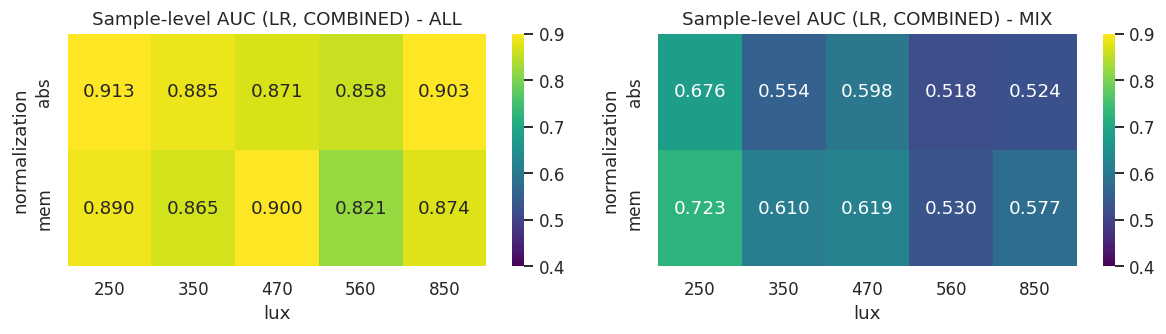

>> Selected condition (criterion: MIX sample-level AUC): lux = 250, normalization = mem  (AUC = 0.723)


In [20]:
t0 = time.time(); scr = []
for prot in ['ALL', 'MIX']:
    for vn in ['abs', 'mem']:
        for lx in CFG['LUX_LEVELS']:
            d = get_df(vn, lx, prot); oof = run_ml_cv(d, NONSHAPE, 'LR', prot, repeats=max(CFG['ML_REPEATS'], 1))
            s, _ = summarize_oof(oof, n_boot=100); scr.append(dict(protocol=prot, normalization=vn, lux=lx, sample_AUC=s['sample_AUC'], sample_AUC_sd=s['sample_AUC_sd'], spot_AUC=s['spot_AUC'], sample_BACC=s['sample_BACC']))
SCR = pd.DataFrame(scr); print(f'Screening finished in {time.time()-t0:.0f}s'); savetab(SCR, 'T08_screening_lux_norm', index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for a_, prot in zip(ax, ['ALL', 'MIX']):
    pv = SCR[SCR.protocol == prot].pivot(index='normalization', columns='lux', values='sample_AUC'); sns.heatmap(pv, annot=True, fmt='.3f', cmap='viridis', vmin=0.4, vmax=0.9, ax=a_); a_.set_title(f'Sample-level AUC (LR, COMBINED) - {prot}')
savefig('F10_screening_heatmap')
best = SCR[SCR.protocol == 'MIX'].sort_values('sample_AUC', ascending=False).iloc[0]
SEL_LUX, SEL_NORM = int(best.lux), str(best.normalization)
print(f'>> Selected condition (criterion: MIX sample-level AUC): lux = {SEL_LUX}, normalization = {SEL_NORM}  (AUC = {best.sample_AUC:.3f})')

### 10.2 Benchmark: feature set × algorithm
Each cell = one full CV experiment (nested tuning). Two protocols are run. The main result is the matrix of **sample-level AUC** (mean over CV repeats).

ALL finished - 2802s cumulative
MIX finished - 5295s cumulative


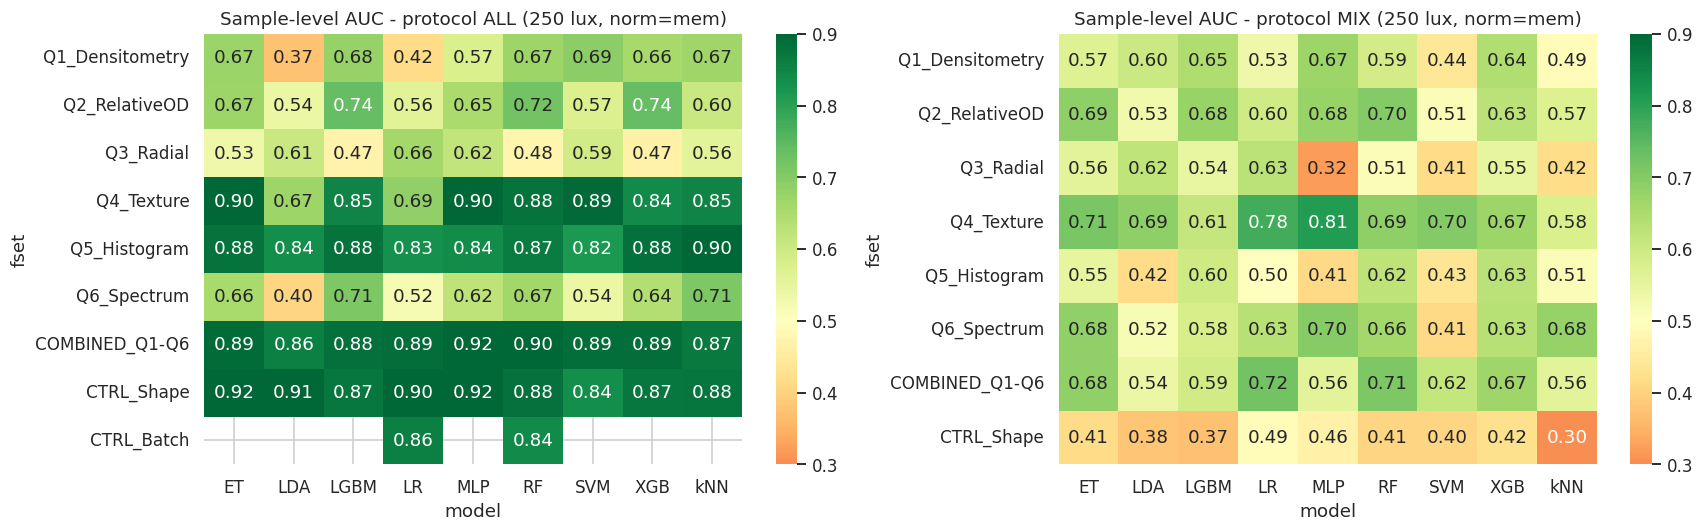

In [22]:
BENCH, OOFS = [], {}
t0 = time.time()
for prot in ['ALL', 'MIX']:
    d = get_df(SEL_NORM, SEL_LUX, prot)
    for fs, cols in FSETS.items():
        if prot == 'MIX' and fs == 'CTRL_Batch': continue
        for mdl in ML_MODELS:
            if fs == 'CTRL_Batch' and mdl not in ('LR', 'RF'): continue
            oof = run_ml_cv(d, cols, mdl, prot); s, cons = summarize_oof(oof)
            BENCH.append(dict(protocol=prot, fset=fs, model=mdl, n_feat=len(cols), **s)); OOFS[(prot, fs, mdl)] = oof
    print(f'{prot} finished - {time.time()-t0:.0f}s cumulative')
BENCH = pd.DataFrame(BENCH); savetab(BENCH, 'T09_ml_benchmark_all', index=False)
pickle.dump(OOFS, open(os.path.join(OUT_DIR, 'cache', 'oofs_ml.pkl'), 'wb'))
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for a_, prot in zip(ax, ['ALL', 'MIX']):
    pv = BENCH[BENCH.protocol == prot].pivot(index='fset', columns='model', values='sample_AUC').reindex(list(FSETS)).dropna(how='all')
    sns.heatmap(pv, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0.3, vmax=0.9, center=0.5, ax=a_); a_.set_title(f'Sample-level AUC - protocol {prot} ({SEL_LUX} lux, norm={SEL_NORM})')
savefig('F11_ml_benchmark_heatmap')

In [23]:
# Summary table: top-8 configurations per protocol (non-control) + best control
cols_show = ['fset','model','n_feat','sample_AUC','sample_AUC_ci_lo','sample_AUC_ci_hi','sample_BACC','sample_SENS','sample_SPEC','sample_F1','sample_MCC','spot_AUC','spot_BACC']
for prot in ['ALL', 'MIX']:
    b = BENCH[BENCH.protocol == prot]; real = b[~b.fset.str.startswith('CTRL')].sort_values('sample_AUC', ascending=False)
    print(f'\n##### {prot}: best configurations (non-control)'); print(real.head(8)[cols_show].round(3).to_string(index=False))
    ctr = b[b.fset.str.startswith('CTRL')].sort_values('sample_AUC', ascending=False)
    print(f'--- best controls ({prot})'); print(ctr.head(3)[cols_show].round(3).to_string(index=False))
# summaries per feature family (mean over all models) and per algorithm (mean over all non-control features)
fam = BENCH.groupby(['protocol', 'fset']).sample_AUC.agg(['mean', 'max']).round(3).unstack(0); print('\nSample-level AUC per feature set (mean/max across models):'); print(fam)
alg = BENCH[~BENCH.fset.str.startswith('CTRL')].groupby(['protocol', 'model']).sample_AUC.agg(['mean', 'max']).round(3).unstack(0); print('\nSample-level AUC per algorithm (non-control):'); print(alg)


##### ALL: best configurations (non-control)
          fset model  n_feat  sample_AUC  sample_AUC_ci_lo  sample_AUC_ci_hi  sample_BACC  sample_SENS  sample_SPEC  sample_F1  sample_MCC  spot_AUC  spot_BACC
COMBINED_Q1-Q6   MLP      79       0.919             0.830             0.989        0.840        0.823        0.857      0.873       0.643     0.798      0.701
    Q4_Texture    ET      26       0.902             0.830             0.989        0.846        0.906        0.786      0.906       0.692     0.717      0.660
  Q5_Histogram   kNN      16       0.897             0.799             0.975        0.824        0.792        0.857      0.854       0.609     0.781      0.693
    Q4_Texture   MLP      26       0.897             0.788             0.987        0.793        0.896        0.690      0.882       0.599     0.746      0.661
COMBINED_Q1-Q6    RF      79       0.896             0.806             0.980        0.838        0.771        0.905      0.850       0.628     0.803      

### 10.3 ROC curves, test against the artefact control, and classification feasibility

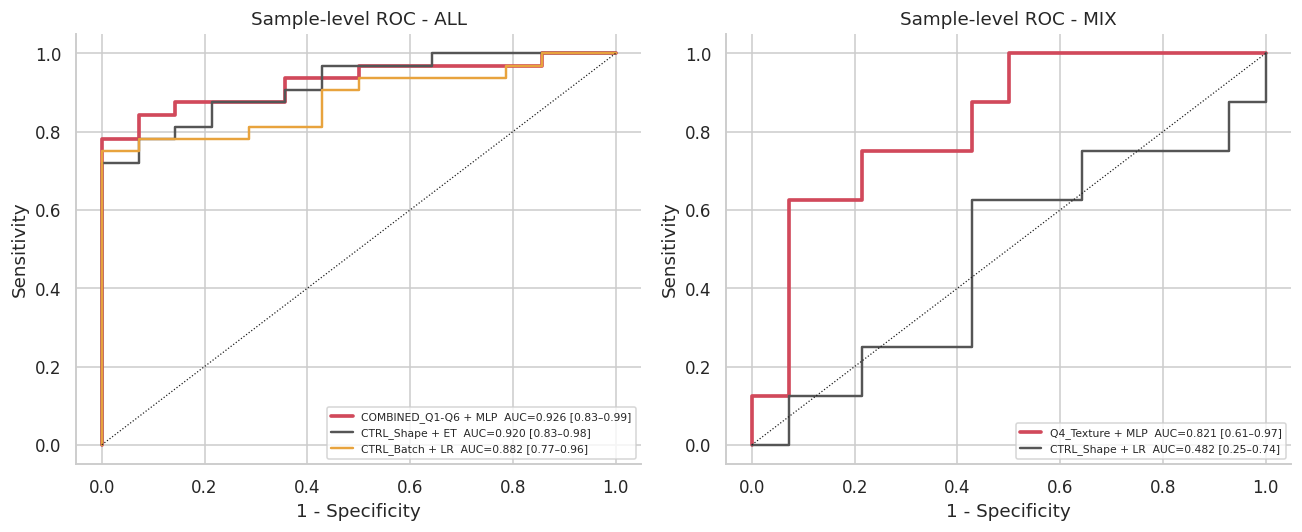

ALL: ΔAUC (best COMBINED_Q1-Q6+MLP - shape-only ET) = +0.011  CI95% [-0.071, +0.100]  p_boot≈0.864
MIX: ΔAUC (best Q4_Texture+MLP - shape-only LR) = +0.340  CI95% [-0.018, +0.661]  p_boot≈0.066


In [24]:
def cons_scores(prot, fs, mdl):
    oof = OOFS[(prot, fs, mdl)]; return oof.groupby('sample_id').agg(y=('y','first'), score=('score','mean'))
def best_cfg(prot, exclude_ctrl=True):
    b = BENCH[BENCH.protocol == prot]; b = b[~b.fset.str.startswith('CTRL')] if exclude_ctrl else b
    r = b.sort_values('sample_AUC', ascending=False).iloc[0]; return r.fset, r.model
fig, ax = plt.subplots(1, 2, figsize=(12, 5)); paired = []
for a_, prot in zip(ax, ['ALL', 'MIX']):
    fs, mdl = best_cfg(prot); sh = BENCH[(BENCH.protocol == prot) & (BENCH.fset == 'CTRL_Shape')].sort_values('sample_AUC', ascending=False).iloc[0]
    lines = [(f'{fs} + {mdl}', cons_scores(prot, fs, mdl), '#d1495b', 2.4), (f'CTRL_Shape + {sh.model}', cons_scores(prot, 'CTRL_Shape', sh.model), '#555555', 1.6)]
    if prot == 'ALL':
        bt = BENCH[(BENCH.protocol == prot) & (BENCH.fset == 'CTRL_Batch')].sort_values('sample_AUC', ascending=False).iloc[0]; lines.append((f'CTRL_Batch + {bt.model}', cons_scores(prot, 'CTRL_Batch', bt.model), '#e8a33d', 1.6))
    for nm, c, col, lw in lines:
        fpr, tpr, _ = roc_curve(c.y, c.score); ci, _ = cluster_boot_auc(c.y.values, c.score.values, CFG['N_BOOT']); a_.plot(fpr, tpr, color=col, lw=lw, label=f'{nm}  AUC={fast_auc(c.y, c.score):.3f} [{ci[0]:.2f}–{ci[1]:.2f}]')
    a_.plot([0, 1], [0, 1], 'k:', lw=0.8); a_.set_xlabel('1 - Specificity'); a_.set_ylabel('Sensitivity'); a_.set_title(f'Sample-level ROC - {prot}'); a_.legend(fontsize=7, loc='lower right')
savefig('F12_roc_best_vs_controls')

# Paired test (cluster bootstrap): AUC of best configuration − AUC of shape control, on the same samples
def paired_boot_diff(c1, c2, n_boot, seed=1):
    j = c1.join(c2, lsuffix='_a', rsuffix='_b', how='inner'); y = j.y_a.values; rng = np.random.default_rng(seed)
    i1, i0 = np.where(y == 1)[0], np.where(y == 0)[0]; diffs = []
    for _ in range(n_boot):
        ii = np.r_[rng.choice(i1, len(i1)), rng.choice(i0, len(i0))]; diffs.append(fast_auc(y[ii], j.score_a.values[ii]) - fast_auc(y[ii], j.score_b.values[ii]))
    diffs = np.array(diffs); return float(np.nanmean(diffs)), np.nanpercentile(diffs, [2.5, 97.5]), float(2 * min((diffs <= 0).mean(), (diffs >= 0).mean()))
for prot in ['ALL', 'MIX']:
    fs, mdl = best_cfg(prot); sh = BENCH[(BENCH.protocol == prot) & (BENCH.fset == 'CTRL_Shape')].sort_values('sample_AUC', ascending=False).iloc[0]
    dm, ci, p = paired_boot_diff(cons_scores(prot, fs, mdl), cons_scores(prot, 'CTRL_Shape', sh.model), CFG['N_BOOT'])
    print(f'{prot}: ΔAUC (best {fs}+{mdl} - shape-only {sh.model}) = {dm:+.3f}  CI95% [{ci[0]:+.3f}, {ci[1]:+.3f}]  p_boot≈{p:.3f}')

### 10.4 Multi-illumination fusion (no lux selection)
Each spot is represented by the features from all five lux levels (ratios/changes across lux are thereby represented). Spots that fail QC at some lux levels are imputed (median of the **training fold**). This is a selection-free analysis with respect to the lux level.

In [25]:
def fuse(variant, cols, protocol):
    d = VARIANTS[variant]; d = d if protocol == 'ALL' else d[d.membrane != 1]
    parts = []
    for lx in CFG['LUX_LEVELS']:
        s = d[d.lux == lx].set_index('spot_id')[cols]; s.columns = [f'{c}@{lx}' for c in s.columns]; parts.append(s)
    wide = pd.concat(parts, axis=1)
    info = d.drop_duplicates('spot_id').set_index('spot_id')[['sample_id', 'membrane', 'y']]
    out = info.join(wide); out.index.name = 'image_id'; return out, [c for c in out.columns if '@' in c]
FUS = []
for prot in ['ALL', 'MIX']:
    W, wcols = fuse(SEL_NORM, NONSHAPE, prot)
    for mdl in [m for m in ML_MODELS if m in ('LR', 'SVM', 'RF', 'XGB', 'LGBM')]:
        oof = run_ml_cv(W, wcols, mdl, prot); s, _ = summarize_oof(oof); FUS.append(dict(protocol=prot, model=mdl, n_feat=len(wcols), **s)); OOFS[(prot, 'FUSION_5lux', mdl)] = oof
FUS = pd.DataFrame(FUS); savetab(FUS, 'T10_ml_fusion', index=False)
print(FUS[['protocol','model','n_feat','sample_AUC','sample_AUC_ci_lo','sample_AUC_ci_hi','sample_BACC','sample_SENS','sample_SPEC','spot_AUC']].round(3).to_string(index=False))

protocol model  n_feat  sample_AUC  sample_AUC_ci_lo  sample_AUC_ci_hi  sample_BACC  sample_SENS  sample_SPEC  spot_AUC
     ALL    LR     395       0.866             0.781             0.969        0.821        0.760        0.881     0.754
     ALL   SVM     395       0.879             0.757             0.967        0.779        0.844        0.714     0.758
     ALL    RF     395       0.899             0.804             0.978        0.830        0.802        0.857     0.801
     ALL   XGB     395       0.908             0.815             0.980        0.885        0.771        1.000     0.804
     ALL  LGBM     395       0.888             0.766             0.971        0.842        0.802        0.881     0.785
     MIX    LR     395       0.643             0.402             0.893        0.634        0.458        0.810     0.590
     MIX   SVM     395       0.548             0.366             0.839        0.542        0.083        1.000     0.539
     MIX    RF     395       0.640      

### 10.5 Label-permutation test (sanity control) and dose–response evidence
* **Permutation test:** class labels are shuffled **at the serum level** (consistently for all replicates) and the whole CV procedure is repeated → distribution of AUC under H₀. P = (1 + #{AUC_perm ≥ AUC_obs}) / (1 + N).
* **Biological dose–response:** if the model truly reads the quantity of bound antibody, the model score in positive sera should correlate with the IgG titre (Spearman). This cannot be produced by a shape artefact.

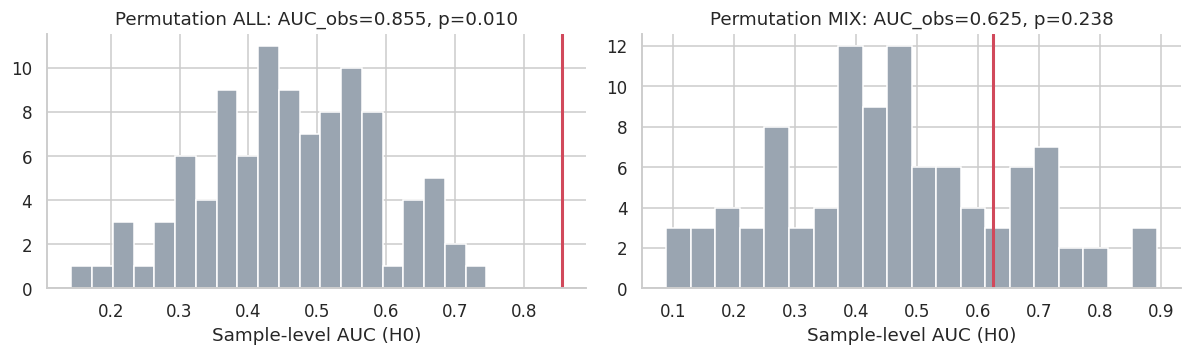

       obs      p  null_mean  null_q95
ALL  0.855  0.010      0.462     0.668
MIX  0.625  0.238      0.464     0.769
Shape-only LR ALL: AUC=0.915, p_perm=0.010
Shape-only LR MIX: AUC=0.482, p_perm=0.525


In [26]:
def perm_test(df, cols, protocol, model='LR', fixed=None, n_perm=None):
    n_perm = n_perm or CFG['N_PERM']; s = protocol_samples(protocol); rng = np.random.default_rng(CFG['SEED'])
    def one(seed, perm):
        y_map = dict(zip(s.sample_id, rng_y(seed) if perm else s.y.values));
        oof = run_ml_cv(df, cols, model, protocol, repeats=1, tune=False, fixed=fixed, y_override=y_map, n_jobs=1)
        c = oof.groupby('sample_id').agg(y=('y','first'), score=('score','mean')); return fast_auc(c.y, c.score)
    ys = s.y.values
    def rng_y(seed): return np.random.default_rng(seed).permutation(ys)
    obs = one(0, False); perms = Parallel(n_jobs=CFG['N_JOBS'])(delayed(one)(1000 + i, True) for i in range(n_perm))
    perms = np.array(perms); return obs, perms, (1 + np.sum(perms >= obs)) / (1 + len(perms))
PERM = {}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a_, prot in zip(ax, ['ALL', 'MIX']):
    d = get_df(SEL_NORM, SEL_LUX, prot); obs, perms, p = perm_test(d, NONSHAPE, prot, 'LR', fixed={'clf__C': 0.01}); PERM[prot] = dict(obs=obs, p=p, null_mean=perms.mean(), null_q95=np.percentile(perms, 95))
    a_.hist(perms, bins=20, color='#9aa5b1'); a_.axvline(obs, color='#d1495b', lw=2); a_.set_title(f'Permutation {prot}: AUC_obs={obs:.3f}, p={p:.3f}'); a_.set_xlabel('Sample-level AUC (H0)')
savefig('F13_permutation'); print(pd.DataFrame(PERM).T.round(3)); savetab(pd.DataFrame(PERM).T, 'T11_permutation')
# Shape-only on the same permutations (what does the shape artefact 'buy'?)
for prot in ['ALL', 'MIX']:
    d = get_df(SEL_NORM, SEL_LUX, prot); o, pm, p = perm_test(d, GROUPS['CTRL_Shape'], prot, 'LR', fixed={'clf__C': 0.1}); print(f'Shape-only LR {prot}: AUC={o:.3f}, p_perm={p:.3f}')

In [27]:
# Dose–response: correlation of the OOF (consensus) score with log10 IgG in POSITIVE sera (sample level)
rows = []
for prot in ['ALL', 'MIX']:
    fs, mdl = best_cfg(prot)
    for nm, key in [(f'{fs}+{mdl}', (prot, fs, mdl)), ('CTRL_Shape(best)', (prot, 'CTRL_Shape', BENCH[(BENCH.protocol==prot)&(BENCH.fset=='CTRL_Shape')].sort_values('sample_AUC').iloc[-1].model))]:
        c = OOFS[key].groupby('sample_id').agg(y=('y', 'first'), score=('score', 'mean')).join(SAMPLE_INFO[['log10_IgG', 'IgG_censored', 'clia_status']])
        pos = c[(c.y == 1) & (c.clia_status == 'Positive')]; rho, p = stats.spearmanr(pos.score, pos.log10_IgG); rows.append(dict(protocol=prot, model=nm, n_pos=len(pos), spearman_rho=rho, p=p))
DR = pd.DataFrame(rows); print(DR.round(3).to_string(index=False)); savetab(DR, 'T12_dose_response', index=False)

protocol              model  n_pos  spearman_rho     p
     ALL COMBINED_Q1-Q6+MLP     31         0.484 0.006
     ALL   CTRL_Shape(best)     31         0.472 0.007
     MIX     Q4_Texture+MLP      7        -0.357 0.432
     MIX   CTRL_Shape(best)      7         0.143 0.760


,protocol,model,n_pos,spearman_rho,p
0,ALL,COMBINED_Q1-Q6+MLP,31,0.484332,0.005763
1,ALL,CTRL_Shape(best),31,0.472286,0.007304
2,MIX,Q4_Texture+MLP,7,-0.357143,0.431611
3,MIX,CTRL_Shape(best),7,0.142857,0.759945


### 10.6 Feature-family contribution (ablation & *group-permutation importance*)
Because features within a family are correlated, importance is assessed **per family**: (a) *drop-one-family* (AUC when one family is removed from `COMBINED`), (b) *group-permutation importance* — the drop in test-fold AUC when the columns of one family are shuffled together.

In [28]:
def family_permutation_importance(df, protocol, model, n_rep=10):
    fam_cols = OrderedDict((k, v) for k, v in GROUPS.items() if k != 'CTRL_Shape'); cols = NONSHAPE
    X = df[cols].values.astype(float); y = df.y.values; g = df.sample_id.values; col_ix = {c: i for i, c in enumerate(cols)}
    fm = FOLDS[(protocol, 0)]; fold = df.sample_id.map(fm).values; rng = np.random.default_rng(0); imp = defaultdict(list)
    for k in range(CFG['OUTER_FOLDS']):
        tr, te = np.where(fold != k)[0], np.where(fold == k)[0]
        if len(np.unique(y[te])) < 2: continue
        p, est, _ = fit_predict_fold(X[tr], y[tr], g[tr], X[te], model, CFG['SEED'] + k, True); base = fast_auc(y[te], p)
        for fam, fc in fam_cols.items():
            ix = [col_ix[c] for c in fc]; drops = []
            for _ in range(n_rep):
                Xp = X[te].copy(); perm = rng.permutation(len(te)); Xp[:, ix] = Xp[perm][:, ix]
                drops.append(base - fast_auc(y[te], est.predict_proba(Xp)[:, 1]))
            imp[fam].append(np.mean(drops))
    return pd.Series({k: np.mean(v) for k, v in imp.items()})
ABL = []
for prot in ['ALL', 'MIX']:
    fs, mdl = best_cfg(prot); d = get_df(SEL_NORM, SEL_LUX, prot)
    base_auc = BENCH[(BENCH.protocol == prot) & (BENCH.fset == 'COMBINED_Q1-Q6') & (BENCH.model == mdl)].sample_AUC.iloc[0]
    for fam in [k for k in GROUPS if k != 'CTRL_Shape']:
        cols = [c for c in NONSHAPE if c not in GROUPS[fam]]; oof = run_ml_cv(d, cols, mdl, prot); s, _ = summarize_oof(oof, n_boot=50)
        ABL.append(dict(protocol=prot, model=mdl, dropped=fam, sample_AUC=s['sample_AUC'], delta_vs_combined=s['sample_AUC'] - base_auc))
    gi = family_permutation_importance(d, prot, mdl)
    for fam, v in gi.items(): ABL.append(dict(protocol=prot, model=mdl, dropped=f'PERM:{fam}', sample_AUC=np.nan, delta_vs_combined=-v))
ABL = pd.DataFrame(ABL); savetab(ABL, 'T13_family_ablation', index=False); print(ABL.round(3).to_string(index=False))

protocol model              dropped  sample_AUC  delta_vs_combined
     ALL   MLP      Q1_Densitometry       0.886             -0.033
     ALL   MLP        Q2_RelativeOD       0.889             -0.030
     ALL   MLP            Q3_Radial       0.873             -0.046
     ALL   MLP           Q4_Texture       0.858             -0.061
     ALL   MLP         Q5_Histogram       0.894             -0.025
     ALL   MLP          Q6_Spectrum       0.893             -0.026
     ALL   MLP PERM:Q1_Densitometry         NaN             -0.031
     ALL   MLP   PERM:Q2_RelativeOD         NaN             -0.017
     ALL   MLP       PERM:Q3_Radial         NaN             -0.005
     ALL   MLP      PERM:Q4_Texture         NaN             -0.119
     ALL   MLP    PERM:Q5_Histogram         NaN             -0.243
     ALL   MLP     PERM:Q6_Spectrum         NaN             -0.015
     MIX   MLP      Q1_Densitometry       0.494             -0.062
     MIX   MLP        Q2_RelativeOD       0.509             -0

## 11. Pipeline B — CNN classification
**Input.** Grayscale image → spot mask → square *crop* centred on the centroid (half-side = 1.1·R) → *resize* to `CNN_SIZE`² → **OD** → between-membrane equalisation (as chosen in §10.1) → pixels outside the inner ROI = 0. Because of the scaling by R, the spot size and contour shape **cannot** be learned by the CNN; the ROI is always a perfect disk.

**Augmentation (physically valid only):** random rotation 0–360°, *flip*, translation ≤ 4%, scale ±5%, small Gaussian noise. No brightness jitter (brightness = signal).

**Training.** All images (all lux levels) of the training sera are used (natural augmentation across exposures); *early stopping* uses ≈20% of the training sera (split per serum) as validation; AdamW + cosine schedule; class-weighted BCE *loss*. Folds are **identical** to ML repeat 0.

**Architectures (5) + control:** SimpleCNN (from scratch), ResNet18, MobileNetV3-Small, EfficientNet-B0, DenseNet121 (ImageNet weights if `CNN_PRETRAINED`; first layer adapted to 1 channel). ***Mask-only* control:** SimpleCNN with a fixed-scale mask silhouette as input (carrying size + contour) → measures the shape-artefact information available to a CNN.

torch 2.11.0+cu130 | device: cuda | GPU: Tesla T4
CNN tensor: (1296, 96, 96) | range -1.69 6.0 | ROI px: 4336


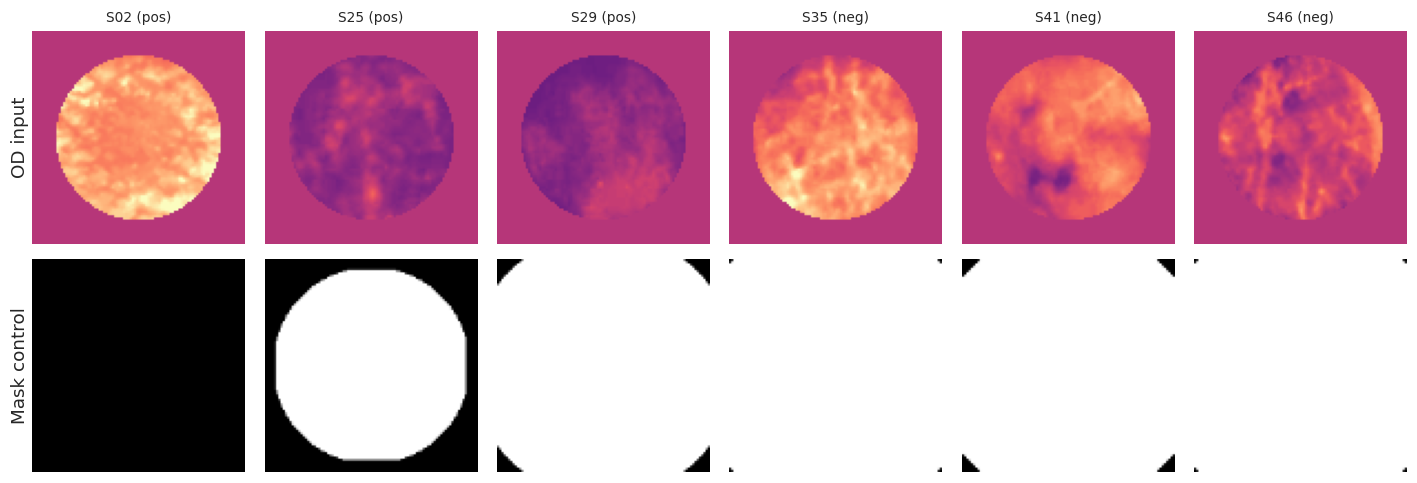

In [29]:
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import models as tvm
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(CFG['SEED']); np.random.seed(CFG['SEED']); torch.backends.cudnn.benchmark = False
print('torch', torch.__version__, '| device:', DEVICE, '| GPU:', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '-')
if DEVICE == 'cpu' and CFG['RUN_MODE'] == 'FULL': print('WARNING: FULL mode without a GPU will be very slow - enable Runtime > GPU in Colab.')

S = CFG['CNN_SIZE']; HALF = 1.1
def build_tensors(vimg):
    # vimg: DataFrame of valid images (VAL); returns the ROI-masked OD tensor and a fixed-scale mask silhouette
    ids, od_list, mk_list = [], [], []
    rr_grid = np.hypot(*(np.mgrid[:S, :S] - (S - 1) / 2)) / ((S / 2) / HALF)          # distance in units of R
    roi_s = rr_grid <= CFG['ROI_FRAC']
    for r in vimg.itertuples():
        a = IMG[r.path]; g = GEO[r.image_id]; od = to_od(a); h = int(round(HALF * g['R']))
        pad = h + 2; odp = np.pad(od, pad, constant_values=0.0); cy, cx = int(round(g['cy'])) + pad, int(round(g['cx'])) + pad
        crop = odp[cy - h:cy + h + 1, cx - h:cx + h + 1]; od_s = resize(crop, (S, S), order=1, anti_aliasing=True).astype(np.float32)
        ids.append(r.image_id); od_list.append(od_s)
        mp = np.pad(MASK[r.image_id].astype(np.float32), 70); cy2, cx2 = int(round(g['cy'])) + 70, int(round(g['cx'])) + 70   # fixed 141-px canvas (absolute scale)
        mk = mp[cy2 - 70:cy2 + 71, cx2 - 70:cx2 + 71]; mk_list.append(resize(mk, (S, S), order=1, anti_aliasing=True).astype(np.float32))
    return ids, np.stack(od_list), np.stack(mk_list), roi_s

CNN_IDS, OD_RAW, MASK_FIXED, ROI_S = build_tensors(VAL)
CNN_META = VAL.set_index('image_id').loc[CNN_IDS][['sample_id', 'spot_id', 'membrane', 'lux', 'y']].copy()
def normalize_cnn(od_raw, meta, mode):
    X = od_raw.copy()
    if mode == 'mem':     # robust centring & scaling per (membrane, lux) using ROI pixels (label-free)
        for (m_, l_), idx in meta.reset_index(drop=True).groupby(['membrane', 'lux']).groups.items():
            v = X[idx][:, ROI_S]; med = np.median(v); sc = 1.4826 * np.median(np.abs(v - np.median(v, axis=1, keepdims=True))) if False else v.std()
            X[idx] = (X[idx] - med) / max(sc, 1e-6)
    else:
        X = (X - np.median(X[:, ROI_S])) / X[:, ROI_S].std()
    X = X * ROI_S[None]; return np.clip(X, -6, 6).astype(np.float32)
X_CNN = normalize_cnn(OD_RAW, CNN_META, SEL_NORM); X_MASK = (MASK_FIXED * 2 - 1).astype(np.float32)
print('CNN tensor:', X_CNN.shape, '| range', X_CNN.min().round(2), X_CNN.max().round(2), '| ROI px:', int(ROI_S.sum()))
fig, ax = plt.subplots(2, 6, figsize=(13, 4.6))
for j, (sid, lab) in enumerate([('S02','pos'), ('S25','pos'), ('S29','pos'), ('S35','neg'), ('S41','neg'), ('S46','neg')]):
    ii = [i for i, (iid, r) in enumerate(CNN_META.iterrows()) if r.sample_id == sid and r.lux == SEL_LUX]
    if ii: ax[0, j].imshow(X_CNN[ii[0]], cmap='magma', vmin=-3, vmax=3); ax[1, j].imshow(X_MASK[ii[0]], cmap='gray'); ax[0, j].set_title(f'{sid} ({lab})', fontsize=9)
    ax[0, j].axis('off'); ax[1, j].axis('off')
ax[0, 0].text(-0.1, 0.5, 'OD input', transform=ax[0, 0].transAxes, rotation=90, va='center'); ax[1, 0].text(-0.1, 0.5, 'Mask control', transform=ax[1, 0].transAxes, rotation=90, va='center')
savefig('F14_cnn_inputs')

In [30]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.f = nn.Sequential(blk(1, 16), blk(16, 32), blk(32, 64), blk(64, 128)); self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 1))
    def forward(self, x): return self.head(self.f(x)).squeeze(1)

def _adapt_first_conv(conv, pretrained):
    new = nn.Conv2d(1, conv.out_channels, conv.kernel_size, conv.stride, conv.padding, bias=conv.bias is not None)
    if pretrained: new.weight.data = conv.weight.data.sum(1, keepdim=True)
    return new

def build_cnn(name, pretrained):
    pretrained = pretrained and name != 'SimpleCNN'
    def W(e):
        if not pretrained: return None
        try: return e.DEFAULT
        except Exception: return None
    try:
        if name == 'SimpleCNN': m = SimpleCNN(); m.target = m.f[-1]; return m
        if name == 'ResNet18':
            m = tvm.resnet18(weights=W(tvm.ResNet18_Weights)); m.conv1 = _adapt_first_conv(m.conv1, pretrained); m.fc = nn.Linear(512, 1); m.target = m.layer4
        elif name == 'MobileNetV3S':
            m = tvm.mobilenet_v3_small(weights=W(tvm.MobileNet_V3_Small_Weights)); m.features[0][0] = _adapt_first_conv(m.features[0][0], pretrained); m.classifier[3] = nn.Linear(1024, 1); m.target = m.features[-1]
        elif name == 'EfficientNetB0':
            m = tvm.efficientnet_b0(weights=W(tvm.EfficientNet_B0_Weights)); m.features[0][0] = _adapt_first_conv(m.features[0][0], pretrained); m.classifier[1] = nn.Linear(1280, 1); m.target = m.features[-1]
        elif name == 'DenseNet121':
            m = tvm.densenet121(weights=W(tvm.DenseNet121_Weights)); m.features.conv0 = _adapt_first_conv(m.features.conv0, pretrained); m.classifier = nn.Linear(1024, 1); m.target = m.features
    except Exception as e:                                    # weights could not be downloaded -> from scratch
        print(f'[{name}] pretrained weights unavailable ({type(e).__name__}); using random initialisation'); return build_cnn_scratch(name)
    return m
def build_cnn_scratch(name): return build_cnn(name, False)

class Wrap(nn.Module):
    def __init__(self, m): super().__init__(); self.m = m; self.target = m.target
    def forward(self, x): o = self.m(x); return o.squeeze(1) if o.ndim > 1 else o

def augment(xb):
    B = xb.size(0); dev = xb.device; th = torch.rand(B, device=dev) * 2 * math.pi; sc = 1 + (torch.rand(B, device=dev) - 0.5) * 0.10
    fl = torch.where(torch.rand(B, device=dev) < 0.5, -1.0, 1.0); tx, ty = [(torch.rand(B, device=dev) - 0.5) * 0.08 for _ in range(2)]
    A = torch.stack([torch.stack([sc * torch.cos(th) * fl, -sc * torch.sin(th), tx], 1), torch.stack([sc * torch.sin(th) * fl, sc * torch.cos(th), ty], 1)], 1)
    out = F.grid_sample(xb, F.affine_grid(A, list(xb.size()), align_corners=False), padding_mode='zeros', align_corners=False); return out + 0.03 * torch.randn_like(out)

@torch.no_grad()
def predict(model, X, bs=256):
    model.eval(); out = []
    for i in range(0, len(X), bs): out.append(torch.sigmoid(model(torch.from_numpy(X[i:i + bs]).unsqueeze(1).to(DEVICE))).float().cpu().numpy())
    return np.concatenate(out)

def train_cnn(name, Xtr, ytr, gtr, seed, pretrained=None, epochs=None):
    pretrained = CFG['CNN_PRETRAINED'] if pretrained is None else pretrained; epochs = epochs or CFG['CNN_EPOCHS']
    torch.manual_seed(seed); np.random.seed(seed)
    # per-serum validation split for early stopping
    sg = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed); tr_i, va_i = next(sg.split(Xtr, ytr, gtr))
    model = Wrap(build_cnn(name, pretrained)).to(DEVICE); lr = 2e-3 if (name == 'SimpleCNN' or not pretrained) else 5e-4
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    pw = torch.tensor((ytr[tr_i] == 0).sum() / max((ytr[tr_i] == 1).sum(), 1), dtype=torch.float32, device=DEVICE); lossf = nn.BCEWithLogitsLoss(pos_weight=pw)
    Xt = torch.from_numpy(Xtr[tr_i]).unsqueeze(1).to(DEVICE); yt = torch.from_numpy(ytr[tr_i].astype(np.float32)).to(DEVICE)
    Xv = torch.from_numpy(Xtr[va_i]).unsqueeze(1).to(DEVICE); yv = torch.from_numpy(ytr[va_i].astype(np.float32)).to(DEVICE)
    scaler = torch.amp.GradScaler(enabled=(DEVICE == 'cuda')); best, best_state, bad, hist = 1e9, None, 0, []
    t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xt), device=DEVICE); tl = 0
        for i in range(0, len(Xt), CFG['CNN_BATCH']):
            b = perm[i:i + CFG['CNN_BATCH']]
            if len(b) < 4: continue
            with torch.autocast(device_type='cuda', enabled=(DEVICE == 'cuda')): loss = lossf(model(augment(Xt[b])), yt[b])
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); tl += loss.item() * len(b)
        sched.step(); model.eval()
        with torch.no_grad(): vl = lossf(model(Xv), yv).item()
        hist.append((tl / len(Xt), vl))
        if vl < best - 1e-4: best, bad, best_state = vl, 0, {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG['CNN_PATIENCE']: break
    model.load_state_dict(best_state); return model, hist, time.time() - t0

def run_cnn_cv(name, protocol, X, input_tag='od', pretrained=None):
    meta = CNN_META[CNN_META.membrane.ne(1) if protocol == 'MIX' else CNN_META.membrane.ge(1)]; ix = np.where(CNN_META.index.isin(meta.index))[0]
    y = CNN_META.y.values[ix]; g = CNN_META.sample_id.values[ix]; fm = FOLDS[(protocol, 0)]; fold = np.array([fm[s] for s in g]); rows, hists, times = [], [], []
    for k in range(CFG['OUTER_FOLDS']):
        tr, te = ix[fold != k], ix[fold == k]
        model, hist, tt = train_cnn(name, X[tr], CNN_META.y.values[tr], CNN_META.sample_id.values[tr], CFG['SEED'] + 10 * k, pretrained)
        t1 = time.time(); p = predict(model, X[te]); inf_ms = 1000 * (time.time() - t1) / len(te)
        rows.append(pd.DataFrame(dict(image_id=CNN_META.index.values[te], sample_id=CNN_META.sample_id.values[te], y=CNN_META.y.values[te], repeat=0, fold=k, score=p, lux=CNN_META.lux.values[te])))
        hists.append(hist); times.append((tt, inf_ms, len(hist)))
        torch.save(model.state_dict(), os.path.join(OUT_DIR, 'models', f'{protocol}_{input_tag}_{name}_fold{k}.pt'))
    n_par = sum(p.numel() for p in model.parameters()); return pd.concat(rows, ignore_index=True), hists, times, n_par

In [31]:
CNN_RES, CNN_OOF, CNN_HIST = [], {}, {}
t0 = time.time()
for prot in CFG['CNN_PROTOCOLS']:
    for name in CFG['CNN_MODELS']:
        oof, hists, times, n_par = run_cnn_cv(name, prot, X_CNN, 'od'); CNN_OOF[(prot, name)] = oof; CNN_HIST[(prot, name)] = hists
        s_all, _ = summarize_oof(oof); sub = oof[oof.lux == SEL_LUX]; s_sel, _ = summarize_oof(sub) if sub.sample_id.nunique() > 3 else (dict.fromkeys(s_all, np.nan), None)
        CNN_RES.append(dict(protocol=prot, model=name, params_M=n_par / 1e6, train_s_per_fold=np.mean([t[0] for t in times]), epochs_run=np.mean([t[2] for t in times]), infer_ms_per_img=np.mean([t[1] for t in times]),
                            **{f'all_{k}': v for k, v in s_all.items()}, **{f'sel_{k}': v for k, v in s_sel.items()}))
        print(f'[{prot}] {name:15s} sample AUC (all lux) = {s_all["sample_AUC"]:.3f}  | at {SEL_LUX} lux = {s_sel["sample_AUC"]:.3f}  | {time.time()-t0:.0f}s')
    if 'SimpleCNN' in CFG['CNN_MODELS'] or True:           # mask-only control
        oof, hists, times, n_par = run_cnn_cv('SimpleCNN', prot, X_MASK, 'mask'); CNN_OOF[(prot, 'CTRL_MaskOnly')] = oof; CNN_HIST[(prot, 'CTRL_MaskOnly')] = hists
        s_all, _ = summarize_oof(oof); CNN_RES.append(dict(protocol=prot, model='CTRL_MaskOnly', params_M=n_par / 1e6, train_s_per_fold=np.mean([t[0] for t in times]), epochs_run=np.mean([t[2] for t in times]),
                                                        infer_ms_per_img=np.mean([t[1] for t in times]), **{f'all_{k}': v for k, v in s_all.items()}))
        print(f'[{prot}] CTRL_MaskOnly sample AUC = {s_all["sample_AUC"]:.3f}')
CNN_RES = pd.DataFrame(CNN_RES); savetab(CNN_RES, 'T14_cnn_benchmark', index=False); pickle.dump((CNN_OOF, CNN_HIST), open(os.path.join(OUT_DIR, 'cache', 'cnn_oof.pkl'), 'wb'))
show = ['protocol', 'model', 'params_M', 'epochs_run', 'train_s_per_fold', 'all_sample_AUC', 'all_sample_AUC_ci_lo', 'all_sample_AUC_ci_hi', 'all_sample_BACC', 'all_sample_SENS', 'all_sample_SPEC', 'all_sample_F1', 'all_spot_AUC']
print(CNN_RES[show].round(3).to_string(index=False))

[ALL] SimpleCNN       sample AUC (all lux) = 0.596  | at 250 lux = 0.569  | 28s
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 170MB/s]


[ALL] ResNet18        sample AUC (all lux) = 0.855  | at 250 lux = 0.812  | 56s
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 62.6MB/s]


[ALL] MobileNetV3S    sample AUC (all lux) = 0.708  | at 250 lux = 0.690  | 82s
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 156MB/s]


[ALL] EfficientNetB0  sample AUC (all lux) = 0.513  | at 250 lux = 0.545  | 127s
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 191MB/s]


[ALL] DenseNet121     sample AUC (all lux) = 0.855  | at 250 lux = 0.855  | 223s
[ALL] CTRL_MaskOnly sample AUC = 0.862
[MIX] SimpleCNN       sample AUC (all lux) = 0.536  | at 250 lux = 0.527  | 266s
[MIX] ResNet18        sample AUC (all lux) = 0.366  | at 250 lux = 0.330  | 288s
[MIX] MobileNetV3S    sample AUC (all lux) = 0.304  | at 250 lux = 0.312  | 307s
[MIX] EfficientNetB0  sample AUC (all lux) = 0.402  | at 250 lux = 0.393  | 339s
[MIX] DenseNet121     sample AUC (all lux) = 0.464  | at 250 lux = 0.527  | 399s
[MIX] CTRL_MaskOnly sample AUC = 0.536
protocol          model  params_M  epochs_run  train_s_per_fold  all_sample_AUC  all_sample_AUC_ci_lo  all_sample_AUC_ci_hi  all_sample_BACC  all_sample_SENS  all_sample_SPEC  all_sample_F1  all_spot_AUC
     ALL      SimpleCNN     0.294        17.0             5.330           0.596                 0.411                 0.775            0.654            0.594            0.714          0.691         0.539
     ALL       ResNet18    1

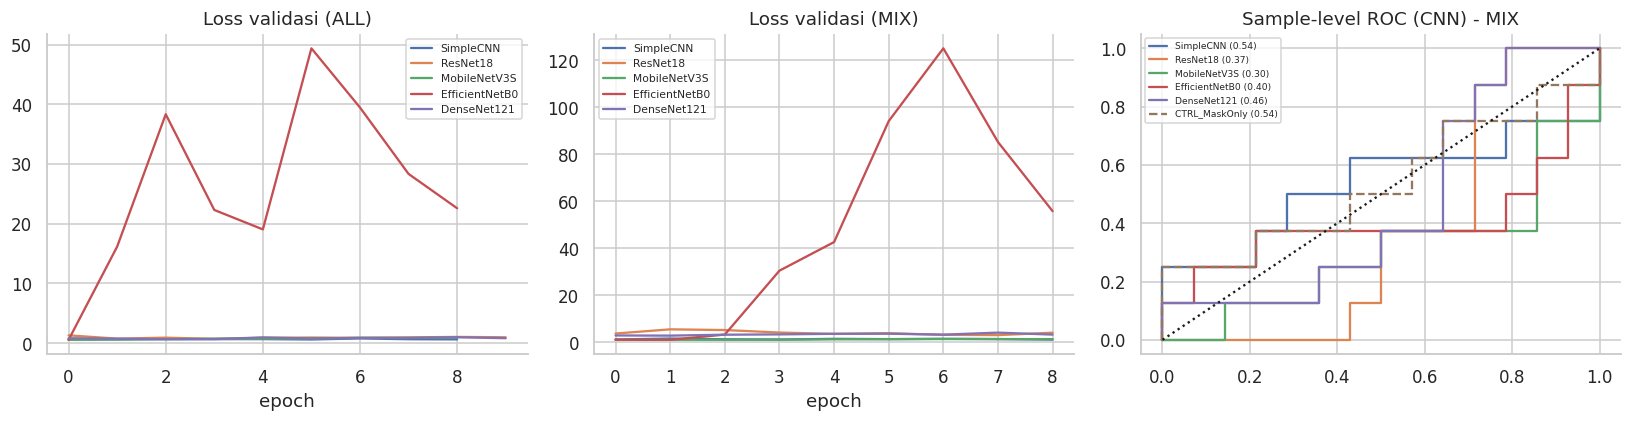

In [32]:
# Learning curves (fold mean) and CNN ROC
fig, ax = plt.subplots(1, len(CFG['CNN_PROTOCOLS']) + 1, figsize=(5 * (len(CFG['CNN_PROTOCOLS']) + 1), 4))
for j, prot in enumerate(CFG['CNN_PROTOCOLS']):
    for name in CFG['CNN_MODELS']:
        h = CNN_HIST[(prot, name)]; L = min(len(x) for x in h); va = np.mean([[e[1] for e in x[:L]] for x in h], 0); ax[j].plot(va, label=name)
    ax[j].set_title(f'Loss validasi ({prot})'); ax[j].set_xlabel('epoch'); ax[j].legend(fontsize=7)
for prot in CFG['CNN_PROTOCOLS']:
    for name in CFG['CNN_MODELS'] + ['CTRL_MaskOnly']:
        c = CNN_OOF[(prot, name)].groupby('sample_id').agg(y=('y', 'first'), score=('score', 'mean')); fpr, tpr, _ = roc_curve(c.y, c.score)
        if prot == CFG['CNN_PROTOCOLS'][-1]: ax[-1].plot(fpr, tpr, label=f'{name} ({fast_auc(c.y, c.score):.2f})', ls='--' if name.startswith('CTRL') else '-')
ax[-1].plot([0, 1], [0, 1], 'k:'); ax[-1].set_title(f'Sample-level ROC (CNN) - {CFG["CNN_PROTOCOLS"][-1]}'); ax[-1].legend(fontsize=6)
savefig('F15_cnn_curves')

### 11.1 Grad-CAM: where does the CNN "look"? (rim-reliance test)
Grad-CAM maps are computed from the model of each fold on that fold's test images. If the model exploits edge artefacts (rim), the attention mass will accumulate in the outer ring of the ROI (ρ > 0.7, which covers ≈51% of the ROI area). A ring-attention-to-area ratio ≈ 1 means uniform attention; > 1 means a bias towards the edge.

Grad-CAM for the best model on protocol MIX : SimpleCNN
Outer ring area = 0.51 of ROI | mean rim_ratio:  {0: 1.124, 1: 1.144} | n = 164


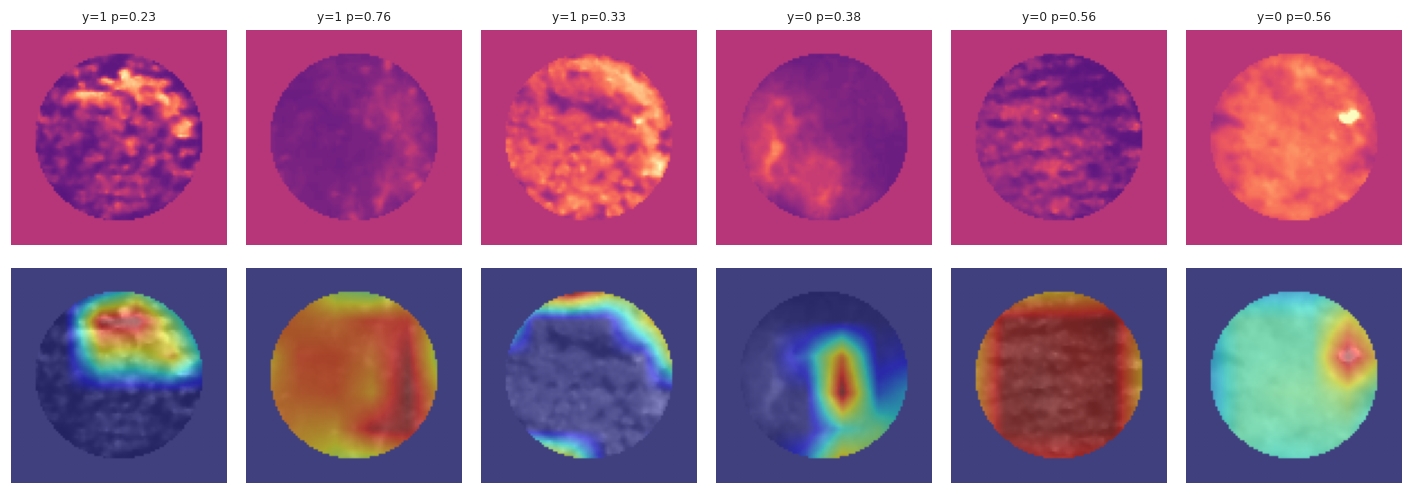

In [33]:
def gradcam_batch(model, X):
    acts, grads = [], []
    def fh(m, i, o): acts.append(o); o.register_hook(lambda g: grads.append(g))
    h = model.target.register_forward_hook(fh); model.eval(); x = torch.from_numpy(X).unsqueeze(1).to(DEVICE).requires_grad_(False)
    out = model(x); model.zero_grad(); out.sum().backward(); h.remove()
    w = grads[0].mean((2, 3), keepdim=True); cam = F.relu((w * acts[0]).sum(1, keepdim=True)); cam = F.interpolate(cam, size=(S, S), mode='bilinear', align_corners=False).squeeze(1)
    cam = cam.detach().cpu().numpy() * ROI_S[None]; cam /= np.maximum(cam.sum((1, 2), keepdims=True), 1e-9); return cam, torch.sigmoid(out).detach().cpu().numpy()

prot_gc = CFG['CNN_PROTOCOLS'][-1]; fm = FOLDS[(prot_gc, 0)]
cand = CNN_RES[(CNN_RES.protocol == prot_gc) & (~CNN_RES.model.str.startswith('CTRL'))].sort_values('all_sample_AUC', ascending=False)
gc_name = cand.model.iloc[0]; print('Grad-CAM for the best model on protocol', prot_gc, ':', gc_name)
rho = np.hypot(*(np.mgrid[:S, :S] - (S - 1) / 2)) / ((S / 2) / HALF) / CFG['ROI_FRAC']; outer = (rho > 0.7) & ROI_S; area_frac = outer.sum() / ROI_S.sum()
cams, rec = [], []
meta_p = CNN_META[CNN_META.membrane.ne(1) if prot_gc == 'MIX' else CNN_META.membrane.ge(1)]; ix_all = np.where(CNN_META.index.isin(meta_p.index))[0]
fold_arr = np.array([fm[s] for s in CNN_META.sample_id.values[ix_all]])
for k in range(CFG['OUTER_FOLDS']):
    model = Wrap(build_cnn(gc_name, False)).to(DEVICE); model.load_state_dict(torch.load(os.path.join(OUT_DIR, 'models', f'{prot_gc}_od_{gc_name}_fold{k}.pt'), map_location=DEVICE))
    te = ix_all[fold_arr == k]; te = te[CNN_META.lux.values[te] == SEL_LUX]
    if len(te) == 0: continue
    cam, p = gradcam_batch(model, X_CNN[te]); cams.append(cam)
    for i, ii in enumerate(te): rec.append(dict(image_id=CNN_META.index[ii], y=CNN_META.y.values[ii], p=p[i], rim_share=cam[i][outer].sum(), rim_ratio=cam[i][outer].sum() / area_frac, idx=ii))
GC = pd.DataFrame(rec); CAMS = np.concatenate(cams)
print(f'Outer ring area = {area_frac:.2f} of ROI | mean rim_ratio: ', GC.groupby('y').rim_ratio.mean().round(3).to_dict(), '| n =', len(GC)); savetab(GC.drop(columns='idx'), 'T15_gradcam_rim_ratio', index=False)
fig, ax = plt.subplots(2, 6, figsize=(13, 4.8)); sel = pd.concat([GC[GC.y == 1].sample(min(3, (GC.y == 1).sum()), random_state=1), GC[GC.y == 0].sample(min(3, (GC.y == 0).sum()), random_state=1)]).reset_index()
for j, r in sel.iterrows():
    ax[0, j].imshow(X_CNN[r.idx], cmap='magma', vmin=-3, vmax=3); ax[0, j].set_title(f"y={int(r.y)} p={r.p:.2f}", fontsize=8); ax[1, j].imshow(X_CNN[r.idx], cmap='gray', vmin=-3, vmax=3); ax[1, j].imshow(CAMS[GC.index[GC.image_id == r.image_id][0]], cmap='jet', alpha=0.5); ax[0, j].axis('off'); ax[1, j].axis('off')
savefig('F16_gradcam_examples')

## 12. ML vs CNN comparison
Both pipelines are compared on **identical folds** (CV repeat 0), at the **serum-sample** unit, for the ALL and MIX protocols. Sample score = mean of its image/spot scores. For ML, the selected lux level (§10.1) is used and, as an information-equivalent comparator to the CNN (which sees all lux levels), the **5-lux fusion** model. Paired comparisons use the cluster bootstrap; classification disagreements are tested with the exact McNemar (binomial) test at the 0.5 threshold.

In [34]:
def cons0(oof):
    o = oof[oof.repeat == 0] if 'repeat' in oof else oof
    return o.groupby('sample_id').agg(y=('y', 'first'), score=('score', 'mean'))
def row_of(label, family, cons, **extra):
    m = bin_metrics(cons.y, cons.score); ci, _ = cluster_boot_auc(cons.y.values, cons.score.values, CFG['N_BOOT'])
    return dict(model=label, family=family, AUC=m['AUC'], AUC_lo=ci[0], AUC_hi=ci[1], BACC=m['BACC'], SENS=m['SENS'], SPEC=m['SPEC'], F1=m['F1'], MCC=m['MCC'], PR_AUC=m['PR_AUC'], Brier=m['Brier'], **extra)
CMP, CONS = [], {}
for prot in CFG['CNN_PROTOCOLS']:
    b = BENCH[(BENCH.protocol == prot) & ~BENCH.fset.str.startswith('CTRL')].sort_values('sample_AUC', ascending=False)
    top, seen = [], set()
    for r in b.itertuples():
        if r.model not in seen: top.append(r); seen.add(r.model)
        if len(top) == 3: break
    for r in top:
        c = cons0(OOFS[(prot, r.fset, r.model)]); CONS[(prot, f'ML: {r.fset}+{r.model}')] = c; CMP.append(dict(protocol=prot, **row_of(f'{r.fset}+{r.model}', 'ML', c, input=f'{SEL_LUX} lux')))
    fu = FUS[FUS.protocol == prot].sort_values('sample_AUC', ascending=False).iloc[0]; c = cons0(OOFS[(prot, 'FUSION_5lux', fu.model)]); CONS[(prot, f'ML: FUSION_5lux+{fu.model}')] = c
    CMP.append(dict(protocol=prot, **row_of(f'FUSION_5lux+{fu.model}', 'ML', c, input='5 lux (fusion)')))
    for sname in [x for x in BENCH[BENCH.protocol == prot].fset.unique() if x.startswith('CTRL')]:
        bb = BENCH[(BENCH.protocol == prot) & (BENCH.fset == sname)].sort_values('sample_AUC', ascending=False).iloc[0]; c = cons0(OOFS[(prot, sname, bb.model)]); CONS[(prot, f'CTRL-ML: {sname}+{bb.model}')] = c
        CMP.append(dict(protocol=prot, **row_of(f'{sname}+{bb.model}', 'CONTROL-ML', c, input=sname)))
    for name in CFG['CNN_MODELS'] + ['CTRL_MaskOnly']:
        c = cons0(CNN_OOF[(prot, name)]); CONS[(prot, f'CNN: {name}')] = c
        rp = CNN_RES[(CNN_RES.protocol == prot) & (CNN_RES.model == name)].iloc[0]
        CMP.append(dict(protocol=prot, **row_of(name, 'CONTROL-CNN' if name.startswith('CTRL') else 'CNN', c, input='all lux' if not name.startswith('CTRL') else 'mask silhouette', params_M=rp.params_M, train_s_per_fold=rp.train_s_per_fold, infer_ms=rp.infer_ms_per_img)))
CMP = pd.DataFrame(CMP); savetab(CMP, 'T16_ml_vs_cnn', index=False)
for prot in CFG['CNN_PROTOCOLS']:
    print(f'\n=========== {prot} ==========='); print(CMP[CMP.protocol == prot].drop(columns='protocol').round(3).to_string(index=False))


=========== ALL ===========
             model      family   AUC  AUC_lo  AUC_hi  BACC  SENS  SPEC    F1   MCC  PR_AUC  Brier           input  params_M  train_s_per_fold  infer_ms
COMBINED_Q1-Q6+MLP          ML 0.929   0.839   0.989 0.835 0.812 0.857 0.867 0.631   0.972  0.110         250 lux       NaN               NaN       NaN
     Q4_Texture+ET          ML 0.929   0.837   0.982 0.846 0.906 0.786 0.906 0.692   0.971  0.178         250 lux       NaN               NaN       NaN
  Q5_Histogram+kNN          ML 0.908   0.817   0.978 0.855 0.781 0.929 0.862 0.659   0.965  0.119         250 lux       NaN               NaN       NaN
   FUSION_5lux+XGB          ML 0.902   0.806   0.975 0.875 0.750 1.000 0.857 0.691   0.964  0.123  5 lux (fusion)       NaN               NaN       NaN
     CTRL_Shape+ET  CONTROL-ML 0.900   0.810   0.973 0.859 0.719 1.000 0.836 0.661   0.961  0.177      CTRL_Shape       NaN               NaN       NaN
     CTRL_Batch+LR  CONTROL-ML 0.854   0.730   0.954 0.875 

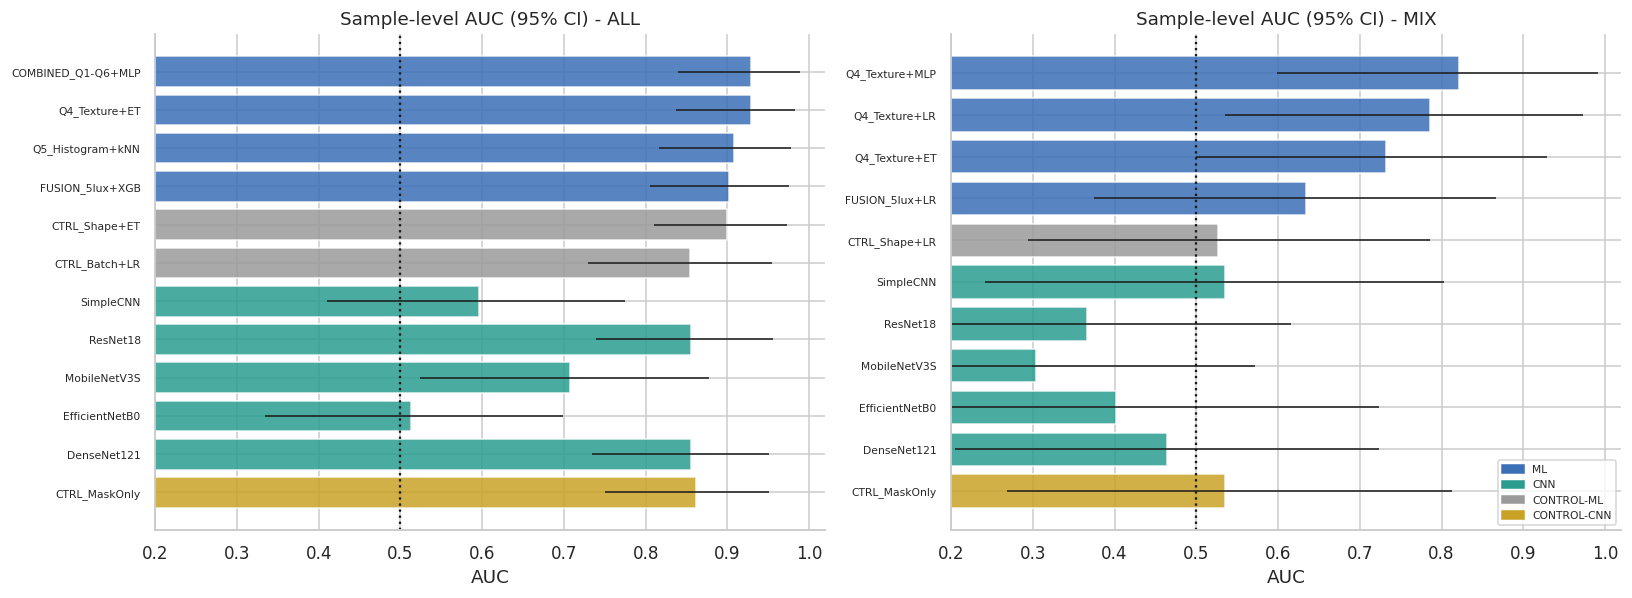

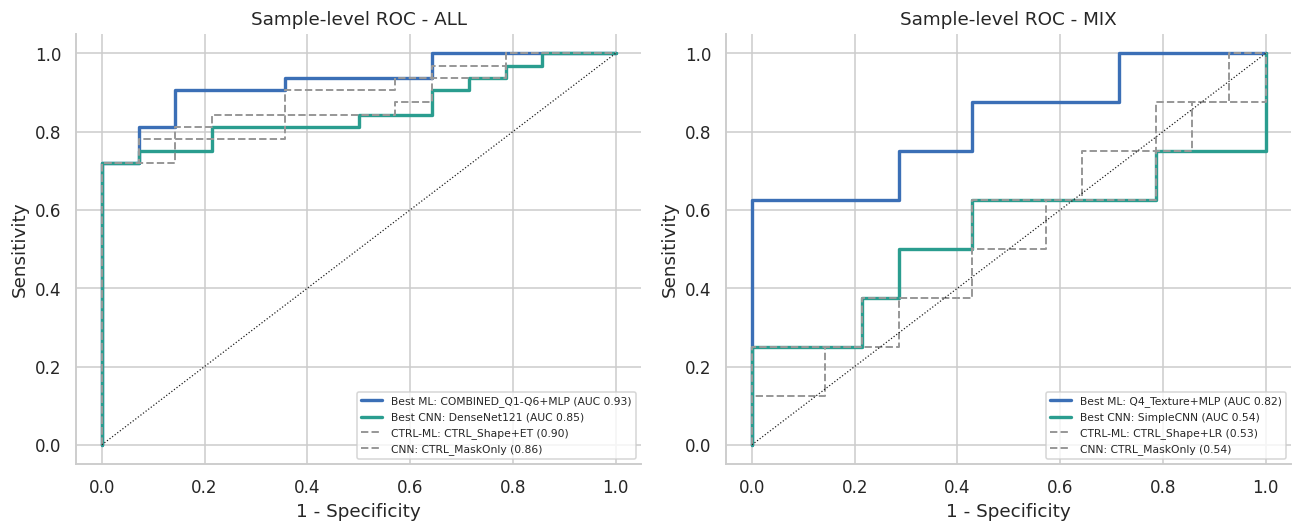

In [35]:
# Visual: AUC + CI per model, grouped by family
pal = {'ML': '#3b6fb6', 'CNN': '#2a9d8f', 'CONTROL-ML': '#9a9a9a', 'CONTROL-CNN': '#c9a227'}
fig, ax = plt.subplots(1, len(CFG['CNN_PROTOCOLS']), figsize=(7.5 * len(CFG['CNN_PROTOCOLS']), 5.6), squeeze=False)
for a_, prot in zip(ax[0], CFG['CNN_PROTOCOLS']):
    d = CMP[CMP.protocol == prot].reset_index(drop=True); y = np.arange(len(d))[::-1]
    a_.barh(y, d.AUC, color=[pal[f] for f in d.family], alpha=0.85); a_.errorbar(d.AUC, y, xerr=[d.AUC - d.AUC_lo, d.AUC_hi - d.AUC], fmt='none', ecolor='k', lw=1)
    a_.set_yticks(y); a_.set_yticklabels(d.model, fontsize=7); a_.axvline(0.5, color='k', ls=':'); a_.set_xlim(0.2, 1.02); a_.set_title(f'Sample-level AUC (95% CI) - {prot}'); a_.set_xlabel('AUC')
from matplotlib.patches import Patch
ax[0, -1].legend(handles=[Patch(color=v, label=k) for k, v in pal.items()], fontsize=7, loc='lower right'); savefig('F17_ml_vs_cnn_auc')

fig, ax = plt.subplots(1, len(CFG['CNN_PROTOCOLS']), figsize=(6 * len(CFG['CNN_PROTOCOLS']), 5), squeeze=False)
for a_, prot in zip(ax[0], CFG['CNN_PROTOCOLS']):
    d = CMP[(CMP.protocol == prot) & CMP.family.isin(['ML', 'CNN'])]; bm = d[d.family == 'ML'].sort_values('AUC').iloc[-1]; bc = d[d.family == 'CNN'].sort_values('AUC').iloc[-1]
    for lab, key, col in [(f'Best ML: {bm.model}', f'ML: {bm.model}', '#3b6fb6'), (f'Best CNN: {bc.model}', f'CNN: {bc.model}', '#2a9d8f')]:
        c = CONS[(prot, key)]; fpr, tpr, _ = roc_curve(c.y, c.score); a_.plot(fpr, tpr, color=col, lw=2.2, label=f'{lab} (AUC {fast_auc(c.y, c.score):.2f})')
    sk = CMP[(CMP.protocol == prot) & (CMP.model.str.startswith('CTRL_Shape'))]
    for k_ in [k for (p_, k) in CONS if p_ == prot and (k.startswith('CTRL-ML: CTRL_Shape') or k == 'CNN: CTRL_MaskOnly')]:
        c = CONS[(prot, k_)]; fpr, tpr, _ = roc_curve(c.y, c.score); a_.plot(fpr, tpr, color='#999', lw=1.3, ls='--', label=f'{k_} ({fast_auc(c.y, c.score):.2f})')
    a_.plot([0, 1], [0, 1], 'k:', lw=0.8); a_.set_title(f'Sample-level ROC - {prot}'); a_.set_xlabel('1 - Specificity'); a_.set_ylabel('Sensitivity'); a_.legend(fontsize=7, loc='lower right')
savefig('F18_roc_ml_vs_cnn')

In [36]:
# Paired tests: best ML vs best CNN; artefact control vs best; exact McNemar
def mcnemar_exact(c1, c2, thr=0.5):
    j = c1.join(c2, lsuffix='_a', rsuffix='_b'); a = ((j.score_a >= thr).astype(int) == j.y_a); b = ((j.score_b >= thr).astype(int) == j.y_a)
    n01, n10 = int((a & ~b).sum()), int((~a & b).sum()); n = n01 + n10
    return n01, n10, (1.0 if n == 0 else min(1.0, 2 * stats.binom.cdf(min(n01, n10), n, 0.5)))
PAIR = []
for prot in CFG['CNN_PROTOCOLS']:
    d = CMP[(CMP.protocol == prot) & CMP.family.isin(['ML', 'CNN'])]; bm = d[d.family == 'ML'].sort_values('AUC').iloc[-1]; bc = d[d.family == 'CNN'].sort_values('AUC').iloc[-1]
    cm, cc = CONS[(prot, f'ML: {bm.model}')], CONS[(prot, f'CNN: {bc.model}')]
    dm, ci, p = paired_boot_diff(cm, cc, CFG['N_BOOT']); n01, n10, pm = mcnemar_exact(cm, cc)
    rho = stats.spearmanr(cm.join(cc, lsuffix='_a', rsuffix='_b').score_a, cm.join(cc, lsuffix='_a', rsuffix='_b').score_b)[0]
    PAIR.append(dict(protocol=prot, A=f'ML {bm.model}', B=f'CNN {bc.model}', dAUC_A_minus_B=dm, ci_lo=ci[0], ci_hi=ci[1], p_boot=p, McNemar_only_A_correct=n01, McNemar_only_B_correct=n10, p_McNemar=pm, spearman_scores=rho))
    for ctrl_key, nm in [(k, k) for (p_, k) in CONS if p_ == prot and k.startswith(('CTRL-ML: CTRL_Shape', 'CNN: CTRL_Mask'))]:
        for lab, c_best in [(f'ML {bm.model}', cm), (f'CNN {bc.model}', cc)]:
            dd, ci2, p2 = paired_boot_diff(c_best, CONS[(prot, ctrl_key)], CFG['N_BOOT']); PAIR.append(dict(protocol=prot, A=lab, B=ctrl_key, dAUC_A_minus_B=dd, ci_lo=ci2[0], ci_hi=ci2[1], p_boot=p2))
PAIR = pd.DataFrame(PAIR); savetab(PAIR, 'T17_paired_tests', index=False); print(PAIR.round(3).to_string(index=False))

protocol                     A                      B  dAUC_A_minus_B  ci_lo  ci_hi  p_boot  McNemar_only_A_correct  McNemar_only_B_correct  p_McNemar  spearman_scores
     ALL ML COMBINED_Q1-Q6+MLP        CNN DenseNet121           0.077 -0.013  0.181   0.114                     3.0                     1.0      0.625            0.714
     ALL ML COMBINED_Q1-Q6+MLP CTRL-ML: CTRL_Shape+ET           0.033 -0.058  0.132   0.532                     NaN                     NaN        NaN              NaN
     ALL       CNN DenseNet121 CTRL-ML: CTRL_Shape+ET          -0.044 -0.156  0.051   0.392                     NaN                     NaN        NaN              NaN
     ALL ML COMBINED_Q1-Q6+MLP     CNN: CTRL_MaskOnly           0.070 -0.018  0.172   0.116                     NaN                     NaN        NaN              NaN
     ALL       CNN DenseNet121     CNN: CTRL_MaskOnly          -0.007 -0.109  0.101   0.906                     NaN                     NaN        NaN          


[ALL] ML=COMBINED_Q1-Q6+MLP | CNN=DenseNet121 | ML errors: 8/46 | CNN errors: 10/46 | errors in both: 7
           y  score_ML  score_CNN code   clia_status      IgG    IgM  err_ML  err_CNN
sample_id                                                                            
S25        1     0.584      0.182   31      Positive  312.000  0.215   False     True
S27        1     0.268      0.476   50      Positive  203.600  0.257    True     True
S28        1     0.381      0.310  N19      Positive   94.480  0.227    True     True
S29        1     0.448      0.266   58      Positive    3.130  0.249    True     True
S30        1     0.477      0.162  N02  Intermediate    1.440  0.212    True     True
S31        1     0.457      0.296   59      Positive   37.960  0.000    True     True
S32        1     0.257      0.358   62      Positive  205.000  0.000    True     True
S33        0     0.652      0.456  N20      Negative    0.130  0.365    True    False
S38        0     0.244      0.528  

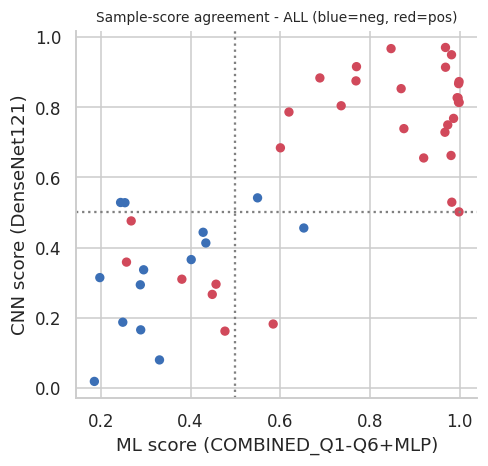


[MIX] ML=Q4_Texture+MLP | CNN=SimpleCNN | ML errors: 5/22 | CNN errors: 12/22 | errors in both: 3
           y  score_ML  score_CNN code   clia_status      IgG    IgM  err_ML  err_CNN
sample_id                                                                            
S26        1     0.464      0.400   34      Positive  367.600  0.223    True     True
S27        1     0.312      0.761   50      Positive  203.600  0.257    True    False
S28        1     0.490      0.531  N19      Positive   94.480  0.227    True    False
S30        1     0.170      0.271  N02  Intermediate    1.440  0.212    True     True
S32        1     0.282      0.199   62      Positive  205.000  0.000    True     True
S33        0     0.421      0.711  N20      Negative    0.130  0.365   False     True
S34        0     0.419      0.526   30      Negative    0.130  0.267   False     True
S35        0     0.269      0.511   54      Negative    0.210  0.364   False     True
S36        0     0.109      0.562   47   

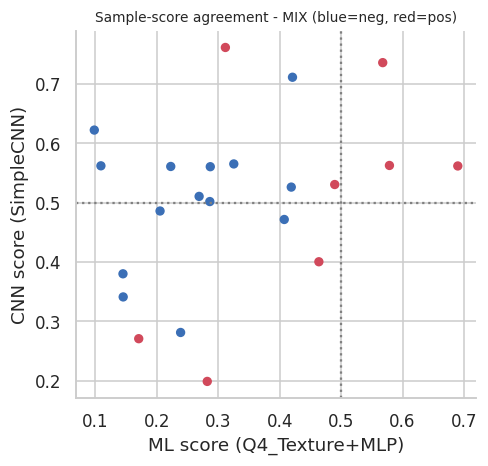

In [37]:
# Sample-level error analysis: which sera are misclassified by the best ML and CNN?
for prot in CFG['CNN_PROTOCOLS']:
    d = CMP[(CMP.protocol == prot) & CMP.family.isin(['ML', 'CNN'])]; bm = d[d.family == 'ML'].sort_values('AUC').iloc[-1]; bc = d[d.family == 'CNN'].sort_values('AUC').iloc[-1]
    E = CONS[(prot, f'ML: {bm.model}')].rename(columns={'score': 'score_ML'}).join(CONS[(prot, f'CNN: {bc.model}')][['score']].rename(columns={'score': 'score_CNN'})).join(SAMPLE_INFO[['code', 'clia_status', 'IgG', 'IgM']])
    E['err_ML'] = ((E.score_ML >= 0.5).astype(int) != E.y); E['err_CNN'] = ((E.score_CNN >= 0.5).astype(int) != E.y)
    print(f'\n[{prot}] ML={bm.model} | CNN={bc.model} | ML errors: {int(E.err_ML.sum())}/{len(E)} | CNN errors: {int(E.err_CNN.sum())}/{len(E)} | errors in both: {int((E.err_ML & E.err_CNN).sum())}')
    print(E[E.err_ML | E.err_CNN].round(3).to_string()); savetab(E.round(4), f'T18_error_analysis_{prot}')
    fig, ax = plt.subplots(figsize=(4.6, 4.4)); ax.scatter(E.score_ML, E.score_CNN, c=E.y.map({0: '#3b6fb6', 1: '#d1495b'}), s=26); ax.axhline(0.5, ls=':', c='gray'); ax.axvline(0.5, ls=':', c='gray')
    ax.set_xlabel(f'ML score ({bm.model})'); ax.set_ylabel(f'CNN score ({bc.model})'); ax.set_title(f'Sample-score agreement - {prot} (blue=neg, red=pos)', fontsize=9); savefig(f'F19_score_agreement_{prot}')

## 13. Sensitivity & robustness analyses
(a) Exclusion of the *intermediate* serum (S30); (b) robustness to the illumination level: the best ML model is run at each lux level and the CNN AUC per lux level is taken from the OOF predictions; (c) spot-level vs sample-level gap.

protocol                  model  AUC_all  AUC_excl_S30
     ALL ML: COMBINED_Q1-Q6+MLP    0.929         0.931
     ALL      ML: Q4_Texture+ET    0.929         0.940
     ALL   ML: Q5_Histogram+kNN    0.908         0.910
     ALL    ML: FUSION_5lux+XGB    0.902         0.901
     ALL CTRL-ML: CTRL_Shape+ET    0.900         0.899
     ALL CTRL-ML: CTRL_Batch+LR    0.854         0.879
     ALL         CNN: SimpleCNN    0.596         0.606
     ALL          CNN: ResNet18    0.855         0.857
     ALL      CNN: MobileNetV3S    0.708         0.712
     ALL    CNN: EfficientNetB0    0.513         0.525
     ALL       CNN: DenseNet121    0.855         0.878
     ALL     CNN: CTRL_MaskOnly    0.862         0.862
     MIX     ML: Q4_Texture+MLP    0.821         0.898
     MIX      ML: Q4_Texture+LR    0.786         0.878
     MIX      ML: Q4_Texture+ET    0.732         0.735
     MIX     ML: FUSION_5lux+LR    0.634         0.633
     MIX CTRL-ML: CTRL_Shape+LR    0.527         0.520
     MIX  

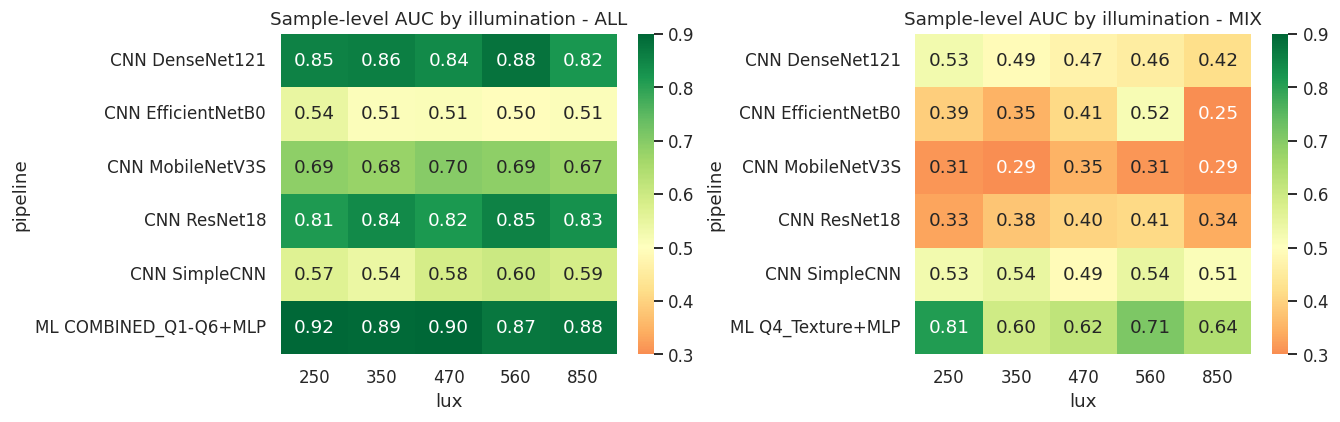

In [38]:
SENS = []
for prot in CFG['CNN_PROTOCOLS']:
    for key in [k for (p_, k) in CONS if p_ == prot]:
        c = CONS[(prot, key)]; c2 = c.drop(index='S30', errors='ignore'); SENS.append(dict(protocol=prot, model=key, AUC_all=fast_auc(c.y, c.score), AUC_excl_S30=fast_auc(c2.y, c2.score)))
SENS = pd.DataFrame(SENS); savetab(SENS, 'T19_sensitivity_excl_S30', index=False); print(SENS.round(3).to_string(index=False))

# (b) robustness across lux levels
LUXR = []
for prot in CFG['CNN_PROTOCOLS']:
    fs, mdl = best_cfg(prot)
    for lx in CFG['LUX_LEVELS']:
        oof = run_ml_cv(get_df(SEL_NORM, lx, prot), FSETS[fs], mdl, prot); s, _ = summarize_oof(oof, n_boot=50); LUXR.append(dict(protocol=prot, pipeline=f'ML {fs}+{mdl}', lux=lx, sample_AUC=s['sample_AUC']))
    for name in CFG['CNN_MODELS']:
        o = CNN_OOF[(prot, name)]
        for lx in CFG['LUX_LEVELS']:
            c = o[o.lux == lx].groupby('sample_id').agg(y=('y', 'first'), score=('score', 'mean')); LUXR.append(dict(protocol=prot, pipeline=f'CNN {name}', lux=lx, sample_AUC=fast_auc(c.y, c.score)))
LUXR = pd.DataFrame(LUXR); savetab(LUXR, 'T20_robustness_lux', index=False)
fig, ax = plt.subplots(1, len(CFG['CNN_PROTOCOLS']), figsize=(6.2 * len(CFG['CNN_PROTOCOLS']), 4), squeeze=False)
for a_, prot in zip(ax[0], CFG['CNN_PROTOCOLS']):
    pv = LUXR[LUXR.protocol == prot].pivot(index='pipeline', columns='lux', values='sample_AUC'); sns.heatmap(pv, annot=True, fmt='.2f', cmap='RdYlGn', center=0.5, vmin=0.3, vmax=0.9, ax=a_); a_.set_title(f'Sample-level AUC by illumination - {prot}')
savefig('F20_robustness_lux')

## 14. Automatic synthesis & export of results
The following cell builds **conditional conclusions** from the numerical results (not fixed text), saves all tables/figures/models to `OUT_DIR`, and creates `RESULTS_SUMMARY.md` and a ZIP archive that serve as input for preparing the manuscript.

In [39]:
def md_table(df, floatfmt='{:.3f}'):
    cols = list(df.columns); out = ['| ' + ' | '.join(map(str, cols)) + ' |', '|' + '|'.join(['---'] * len(cols)) + '|']
    for _, r in df.iterrows(): out.append('| ' + ' | '.join(floatfmt.format(v) if isinstance(v, (float, np.floating)) and np.isfinite(v) else str(v) for v in r.values) + ' |')
    return '\n'.join(out)
lines = ['# AUTOMATIC RESULTS SUMMARY', f'Generated: {time.strftime("%Y-%m-%d %H:%M")} | mode={CFG["RUN_MODE"]} | selected lux={SEL_LUX} | normalization={SEL_NORM}', '']
lines += ['## Data', f'- Images: {len(IDX)} (valid: {int(IDX.valid.sum())}; failed QC: {int((~IDX.valid).sum())}); unique spots: {IDX.spot_id.nunique()}; sera: {IDX.sample_id.nunique()} (positive {int(META.y.sum())}, negative {int((1-META.y).sum())}).', '']
lines += ['## Artefact diagnostic (univariate AUC of crop size @850 lux)', md_table(diag.reset_index()), '']
verdict = []
for prot in CFG['CNN_PROTOCOLS']:
    d = CMP[CMP.protocol == prot]; real = d[d.family.isin(['ML', 'CNN'])].sort_values('AUC', ascending=False).iloc[0]; ctrl = d[d.family.str.startswith('CONTROL')].sort_values('AUC', ascending=False).iloc[0]
    pe = PERM.get(prot, {}); sig = real.AUC_lo > 0.5
    verdict.append(f'- **{prot}**: best {real.family} model `{real.model}` sample AUC = {real.AUC:.3f} (95% CI {real.AUC_lo:.3f}-{real.AUC_hi:.3f}); best artefact control `{ctrl.model}` AUC = {ctrl.AUC:.3f}. ' +
                   ('Lower CI bound > 0.5 (discrimination above chance). ' if sig else 'CI includes 0.5 (insufficient evidence of discrimination above chance). ') +
                   (f'Permutation test (LR): p = {pe["p"]:.3f}. ' if pe else '') + ('Performance does NOT exceed the artefact control -> cannot be attributed to antibody binding.' if real.AUC <= ctrl.AUC + 0.02 else 'Exceeds the artefact control.'))
lines += ['## Conditional conclusions (automatic)'] + verdict + ['']
for prot in CFG['CNN_PROTOCOLS']: lines += [f'## ML vs CNN comparison - {prot}', md_table(CMP[CMP.protocol == prot].drop(columns='protocol')), '']
lines += ['## Paired tests', md_table(PAIR), '', '## Dose-response (Spearman score vs log10 IgG, positive sera)', md_table(DR), '', '## Feature-family contribution', md_table(ABL), '']
open(os.path.join(OUT_DIR, 'RESULTS_SUMMARY.md'), 'w', encoding='utf-8').write('\n'.join(lines)); print('\n'.join(verdict))

- **ALL**: best ML model `COMBINED_Q1-Q6+MLP` sample AUC = 0.929 (95% CI 0.839-0.989); best artefact control `CTRL_Shape+ET` AUC = 0.900. Lower CI bound > 0.5 (discrimination above chance). Permutation test (LR): p = 0.010. Exceeds the artefact control.
- **MIX**: best ML model `Q4_Texture+MLP` sample AUC = 0.821 (95% CI 0.598-0.991); best artefact control `CTRL_MaskOnly` AUC = 0.536. Lower CI bound > 0.5 (discrimination above chance). Permutation test (LR): p = 0.238. Exceeds the artefact control.


In [40]:
import shutil, subprocess
env = dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__, torch=torch.__version__, torchvision=torchvision.__version__, device=DEVICE)
import sklearn, xgboost, lightgbm, skimage; env.update(sklearn=sklearn.__version__, xgboost=xgboost.__version__, lightgbm=lightgbm.__version__, skimage=skimage.__version__)
json.dump(dict(config=CFG, env=env, selected=dict(lux=SEL_LUX, norm=SEL_NORM), n_images=len(IDX), n_valid=int(IDX.valid.sum())), open(os.path.join(OUT_DIR, 'run_manifest.json'), 'w'), indent=2, default=str)
base = os.path.join(WORK_ROOT if IN_COLAB else os.path.dirname(OUT_DIR.rstrip('/')), 'Dotblot_Results_bundle')
zp = shutil.make_archive(base, 'zip', OUT_DIR); print('Archive:', zp, f'({os.path.getsize(zp)/1e6:.1f} MB)')
print('OUT_DIR contents:', {d: len(os.listdir(os.path.join(OUT_DIR, d))) for d in ['tables', 'figures', 'models', 'cache']})

Archive: /content/drive/MyDrive/Dotblot_GRA7/Dotblot_Results_bundle.zip (917.9 MB)
OUT_DIR contents: {'tables': 24, 'figures': 21, 'models': 60, 'cache': 2}


## 15. Roadmap for manuscript preparation (outputs → manuscript sections)
| Manuscript section | Source in the notebook |
|---|---|
| Methods: data design & ground truth | §2, Tables `T01`, `T03` |
| Methods: acquisition QC & physical pre-processing (inner ROI, OD) | §4–5, `F06`–`F07` |
| Methods: quantification Q1–Q6 + controls | §6, `T04` |
| Methods: normalisation, grouped validation, nested tuning, statistics | §7, §9, §10 |
| Results: data characteristics & **artefact/batch evidence** | §3.3, `T02`, `F04`, `F08`, `T05`, `T06`, `F09` |
| Results: ML | §10 `T08`–`T13`, `F10`–`F13` |
| Results: CNN | §11 `T14`–`T15`, `F14`–`F16` |
| Results: ML vs CNN | §12 `T16`–`T18`, `F17`–`F19` |
| Sensitivity/robustness | §13 `T19`–`T20`, `F20` |
| Discussion/limitations | `RESULTS_SUMMARY.md` (conditional conclusions), number of sera (46; MIX = 22), single centre, retrospective |